# 01. Разведочный анализ `raw_data/` для AIOps

Этот notebook пересобирает первый исследовательский этап ВКР на правильном датасете `raw_data/`.
Старые notebook из `lcman/old_broke_data_pype/` были полезны как методическая траектория, но их кодовые пути и численные результаты относились к другой структуре данных и здесь не переносятся.

**Цель notebook:** описать устройство workload/scenario данных, проверить качество логовой и KPI-модальностей, оценить multi-rate оконную агрегацию и сформулировать правила для следующего notebook `02_multirate_baseline_raw_data.ipynb`.

**Ключевая единица наблюдения дальше:** `run_id = workload/scenario`.

Исследовательские вопросы:

1. Как физически устроен `raw_data/` по workload и scenario?
2. Какие логовые источники доступны, и можно ли строго восстановить scenario на уровне строк parsed logs?
3. Как распределены normal/failure runs и failure families?
4. Какие шаблоны и компоненты доминируют в parsed logs?
5. Как устроены KPI-файлы: hosts, metrics, series, timestamp density?
6. Какие временные окна разумны для логов и KPI?
7. Насколько строго связаны logs и KPI через provenance `workload/scenario`?
8. Какие правила подготовки данных должны перейти в `02`?

## 0. Настройка и методические ограничения

В notebook используются только данные из `raw_data/`. Файл `notebooks_rebuild_map.md` используется как методическая карта пересборки, но не как источник численных результатов.

Важное локальное решение перед EDA:

- `parsed_log/labeled.csv` хранится на уровне workload и содержит поля `Timestamp, Template, Content, Component, Label`, но не содержит явного поля `scenario` для каждой строки.
- Строгий scenario-level provenance доступен через пути `mapred_logs/<scenario>.log` и `kpis/<scenario>/...`.
- Поэтому EDA разделяет:
  - **workload-level parsed log EDA** для `Template`, `Component`, `Label`;
  - **scenario-level raw/KPI EDA** для provenance, длительностей, coverage и future alignment.
- KPI-каталог занимает несколько гигабайт; в `01` выполняется полный path-level inventory и lightweight metadata scan, а value-level статистика считается на репрезентативной выборке файлов. Это исследовательский notebook, а не ETL-скрипт полного training dataset.

In [1]:
from pathlib import Path
from collections import Counter
import json
import math
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
RAW_ROOT = ROOT / "raw_data"
MAP_CANDIDATES = [ROOT / "notebooks_rebuild_map.md", ROOT / "lcman" / "notebooks_rebuild_map.md"]
MAP_PATH = next((p for p in MAP_CANDIDATES if p.exists()), None)
OLD_NOTEBOOK_DIR = ROOT / "lcman" / "old_broke_data_pype"

assert RAW_ROOT.exists(), f"raw_data not found: {RAW_ROOT}"

EXPECTED_KPI_METRICS = {"cpustat", "iostat", "jvms", "memstat", "netstat", "vmstat"}
WINDOW_SECONDS = [10, 30, 60, 300]

# Ограничения value-level KPI EDA: путь и метаданные сканируются полностью,
# значения KPI читаются только из сбалансированной выборки.
KPI_VALUE_SAMPLE_PER_METRIC_FAMILY = 1
KPI_VALUE_SAMPLE_MAX_FILES = 96
KPI_HEAD_TS_SAMPLE = 160

context_df = pd.DataFrame([
    {"object": "project root", "path": str(ROOT), "exists": ROOT.exists()},
    {"object": "raw_data", "path": str(RAW_ROOT), "exists": RAW_ROOT.exists()},
    {"object": "rebuild map", "path": str(MAP_PATH) if MAP_PATH else "not found", "exists": MAP_PATH is not None},
    {"object": "old notebooks", "path": str(OLD_NOTEBOOK_DIR), "exists": OLD_NOTEBOOK_DIR.exists()},
])
display(context_df)

old_notebooks = sorted(OLD_NOTEBOOK_DIR.glob("*.ipynb")) if OLD_NOTEBOOK_DIR.exists() else []
display(pd.DataFrame({"old_notebook": [p.name for p in old_notebooks]}))

,object,path,exists
0,project root,c:\Main\DGTU\ВКР\Diploma,True
1,raw_data,c:\Main\DGTU\ВКР\Diploma\raw_data,True
2,rebuild map,c:\Main\DGTU\ВКР\Diploma\lcman\notebooks_rebuild_map.md,True
3,old notebooks,c:\Main\DGTU\ВКР\Diploma\lcman\old_broke_data_pype,True


,old_notebook
0,01_eda.ipynb
1,02_multimodal_pipeline_baseline.ipynb
2,03_lightweight_multimodal_system.ipynb


In [2]:
def safe_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []
    return sorted([p for p in path.iterdir() if p.is_dir() and not p.name.startswith(".")], key=lambda p: p.name)


def safe_files(path: Path, pattern="*"):
    if not path.exists() or not path.is_dir():
        return []
    return sorted([p for p in path.glob(pattern) if p.is_file() and not p.name.startswith(".")], key=lambda p: p.name)


def format_bytes(n):
    if pd.isna(n):
        return np.nan
    n = float(n)
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if abs(n) < 1024:
            return f"{n:,.1f} {unit}"
        n /= 1024
    return f"{n:.1f} PB"


def classify_scenario(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    return "normal" if name.startswith("normal") else "failure"


def failure_family(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    if name.startswith("normal"):
        return "normal"
    if "cpu" in name:
        return "cpu"
    if "memory" in name or "mem" in name or name == "vm_stress" or "vm_" in name:
        return "memory"
    if "io" in name:
        return "io"
    if "net" in name or "lose_package" in name or "mq" in name:
        return "network"
    if "datanode" in name:
        return "datanode"
    if "namenode" in name:
        return "namenode"
    if "nodemanager" in name:
        return "nodemanager"
    if "resourcemanager" in name:
        return "resourcemanager"
    if "master" in name:
        return "master"
    if "worker" in name:
        return "worker"
    if "late" in name or "slow" in name:
        return "timing"
    if "killed" in name:
        return "killed_other"
    if "suspended" in name:
        return "suspended_other"
    return "other"


def failure_mode(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    if name.startswith("normal"):
        return "normal"
    if "killed" in name:
        return "killed"
    if "suspended" in name:
        return "suspended"
    if "stress" in name:
        return "stress"
    if "delay" in name:
        return "delay"
    if "late" in name:
        return "late_sub"
    if "lose" in name:
        return "packet_loss"
    return "other"


def compact_display(df, n=20):
    if df is None or len(df) == 0:
        display(pd.DataFrame())
    else:
        display(df.head(n))
        if len(df) > n:
            display(Markdown(f"Показано {n} строк из {len(df):,}."))

## 1. Инвентаризация `raw_data/`

Первый шаг — не читать отдельные файлы, а построить паспорт датасета. Для ВКР это важно, потому что дальнейшая модельная постановка должна опираться на явную единицу наблюдения и на список исключений, а не на неявные предположения о структуре каталогов.

In [3]:
def scan_raw_data_inventory(raw_root: Path):
    workload_rows = []
    scenario_rows = []
    issue_rows = []

    workloads = safe_dirs(raw_root)
    for wdir in workloads:
        workload = wdir.name
        parsed_dir = wdir / "parsed_log"
        mapred_dir = wdir / "mapred_logs"
        kpis_dir = wdir / "kpis"

        has_bench = (wdir / "bench.log").exists()
        has_mapred_dir = mapred_dir.exists()
        has_parsed_dir = parsed_dir.exists()
        has_labeled = (parsed_dir / "labeled.csv").exists()
        has_normal = (parsed_dir / "normal.csv").exists()
        has_tasks = (parsed_dir / "tasks.csv").exists()
        has_kpis_dir = kpis_dir.exists()

        mapred = {p.stem: p for p in safe_files(mapred_dir, "*.log")}
        kpi_dirs = {p.name: p for p in safe_dirs(kpis_dir)}
        scenario_names = sorted(set(mapred) | set(kpi_dirs))

        if not has_bench:
            issue_rows.append({"level": "workload", "workload": workload, "scenario": None, "issue": "missing bench.log"})
        if not has_labeled:
            issue_rows.append({"level": "workload", "workload": workload, "scenario": None, "issue": "missing parsed_log/labeled.csv"})
        for required, exists in {"mapred_logs/": has_mapred_dir, "parsed_log/": has_parsed_dir, "kpis/": has_kpis_dir}.items():
            if not exists:
                issue_rows.append({"level": "workload", "workload": workload, "scenario": None, "issue": f"missing {required}"})

        for scenario in scenario_names:
            kdir = kpi_dirs.get(scenario)
            instruments_dir = kdir / "instruments" if kdir else None
            host_dirs = safe_dirs(instruments_dir) if instruments_dir else []
            metric_names = set()
            instrument_files = 0
            instrument_size = 0
            for hdir in host_dirs:
                for fp in safe_files(hdir):
                    metric_names.add(fp.name)
                    instrument_files += 1
                    try:
                        instrument_size += fp.stat().st_size
                    except OSError:
                        pass
            has_mapred_log = scenario in mapred
            has_kpi_dir = scenario in kpi_dirs
            has_instruments = len(host_dirs) > 0
            has_kpi_measurements = instrument_files > 0

            if has_mapred_log and not has_kpi_dir:
                issue_rows.append({"level": "scenario", "workload": workload, "scenario": scenario, "issue": "mapred log without KPI directory"})
            if has_kpi_dir and not has_mapred_log:
                issue_rows.append({"level": "scenario", "workload": workload, "scenario": scenario, "issue": "KPI directory without mapred log"})
            if has_kpi_dir and not has_kpi_measurements:
                issue_rows.append({"level": "scenario", "workload": workload, "scenario": scenario, "issue": "KPI directory without instrument files"})
            unexpected_metrics = sorted(metric_names - EXPECTED_KPI_METRICS)
            if unexpected_metrics:
                issue_rows.append({"level": "scenario", "workload": workload, "scenario": scenario, "issue": f"unexpected KPI files: {unexpected_metrics}"})

            scenario_rows.append({
                "workload": workload,
                "scenario": scenario,
                "run_id": f"{workload}/{scenario}",
                "scenario_type": classify_scenario(scenario),
                "failure_family": failure_family(scenario),
                "failure_mode": failure_mode(scenario),
                "has_mapred_log": has_mapred_log,
                "has_kpi_dir": has_kpi_dir,
                "has_instruments": has_instruments,
                "has_kpi_measurements": has_kpi_measurements,
                "has_parsed_labeled_workload": has_labeled,
                "has_parsed_normal_workload": has_normal,
                "has_parsed_tasks_workload": has_tasks,
                "host_count": len(host_dirs),
                "metric_count": len(metric_names),
                "metrics": ", ".join(sorted(metric_names)),
                "instrument_files": instrument_files,
                "instrument_size_bytes": instrument_size,
                "strict_path_pair": has_mapred_log and has_kpi_dir and has_kpi_measurements,
            })

        workload_rows.append({
            "workload": workload,
            "has_bench_log": has_bench,
            "has_mapred_logs": has_mapred_dir,
            "has_parsed_log_dir": has_parsed_dir,
            "has_labeled_csv": has_labeled,
            "has_normal_csv": has_normal,
            "has_tasks_csv": has_tasks,
            "has_kpis_dir": has_kpis_dir,
            "mapred_scenarios": len(mapred),
            "kpi_scenarios": len(kpi_dirs),
            "strict_scenarios": int(sum(1 for s in scenario_names if (s in mapred and s in kpi_dirs))),
            "log_only_scenarios": len(set(mapred) - set(kpi_dirs)),
            "kpi_only_scenarios": len(set(kpi_dirs) - set(mapred)),
        })

    dataset_inventory_df = pd.DataFrame(workload_rows).sort_values("workload").reset_index(drop=True)
    scenario_inventory_df = pd.DataFrame(scenario_rows).sort_values(["workload", "scenario"]).reset_index(drop=True)
    inventory_issues_df = pd.DataFrame(issue_rows).sort_values(["level", "workload", "scenario", "issue"], na_position="first").reset_index(drop=True)
    return dataset_inventory_df, scenario_inventory_df, inventory_issues_df


dataset_inventory_df, scenario_inventory_df, inventory_issues_df = scan_raw_data_inventory(RAW_ROOT)

display(Markdown("### Паспорт уровня workload"))
display(dataset_inventory_df)

display(Markdown("### Паспорт уровня scenario: первые строки"))
compact_display(scenario_inventory_df[[
    "workload", "scenario", "scenario_type", "failure_family", "has_mapred_log", "has_kpi_dir",
    "host_count", "metric_count", "instrument_files", "strict_path_pair", "has_parsed_labeled_workload"
]], n=18)

display(Markdown("### Зафиксированные проблемы инвентаризации"))
compact_display(inventory_issues_df, n=30)

### Паспорт уровня workload

,workload,has_bench_log,has_mapred_logs,has_parsed_log_dir,has_labeled_csv,has_normal_csv,has_tasks_csv,has_kpis_dir,mapred_scenarios,kpi_scenarios,strict_scenarios,log_only_scenarios,kpi_only_scenarios
0,aggregation,True,True,True,True,True,True,True,29,29,29,0,0
1,als,True,True,True,True,True,True,True,27,26,26,1,0
2,bayes,True,True,True,True,True,True,True,27,26,26,1,0
3,graph_pagerank,True,True,True,True,True,True,True,29,29,29,0,0
4,join,True,True,True,True,True,True,True,29,29,29,0,0
5,lda,True,True,True,True,True,True,True,26,26,26,0,0
6,nweight,True,True,True,False,True,True,True,22,29,22,0,7
7,repartition,True,True,True,True,True,True,True,28,28,28,0,0
8,rf,True,True,True,True,True,True,True,29,29,29,0,0
9,scan,True,True,True,True,True,True,True,29,29,29,0,0


### Паспорт уровня scenario: первые строки

,workload,scenario,scenario_type,failure_family,has_mapred_log,has_kpi_dir,host_count,metric_count,instrument_files,strict_path_pair,has_parsed_labeled_workload
0,aggregation,2nd_namenode_killed,failure,namenode,True,True,6,6,36,True,True
1,aggregation,2nd_namenode_suspended,failure,namenode,True,True,6,6,36,True,True
2,aggregation,cpu_stress,failure,cpu,True,True,6,6,36,True,True
3,aggregation,datanode_killed,failure,datanode,True,True,6,6,36,True,True
4,aggregation,datanode_suspended,failure,datanode,True,True,6,6,36,True,True
5,aggregation,io_stress,failure,io,True,True,6,6,36,True,True
6,aggregation,late_sub,failure,timing,True,True,6,6,36,True,True
7,aggregation,lose_package,failure,network,True,True,6,6,36,True,True
8,aggregation,master_killed,failure,master,True,True,6,6,36,True,True
9,aggregation,master_suspended,failure,master,True,True,6,6,36,True,True


Показано 18 строк из 449.

### Зафиксированные проблемы инвентаризации

,level,workload,scenario,issue
0,scenario,als,normal6,mapred log without KPI directory
1,scenario,bayes,normal7,mapred log without KPI directory
2,scenario,nweight,normal1,KPI directory without mapred log
3,scenario,nweight,normal2,KPI directory without mapred log
4,scenario,nweight,normal3,KPI directory without mapred log
5,scenario,nweight,normal4,KPI directory without mapred log
6,scenario,nweight,normal5,KPI directory without mapred log
7,scenario,nweight,normal6,KPI directory without mapred log
8,scenario,nweight,normal7,KPI directory without mapred log
9,scenario,web_pagerank,2nd_namenode_killed,unexpected KPI files: ['pgid']


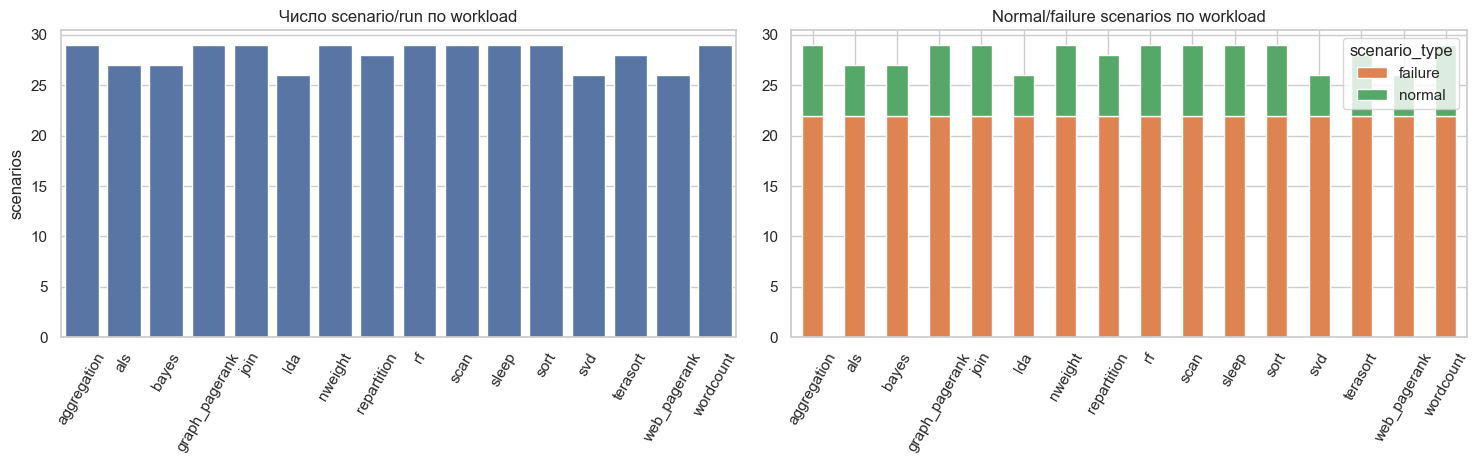


### Локальный вывод раздела

- **Свидетельство:** физический паспорт `raw_data/` на уровнях workload и `(workload, scenario)`. Найдено **16 workload** и **449 scenario/run**. Доля строгих path-based пар logs↔KPI составляет **98.0%**.
- **Решение:** базовая единица анализа для следующих notebook — `(workload, scenario)`, а не один глобальный логовый поток.
- **Следствие:** provenance в новом датасете в основном задан каталогами, поэтому в `02` нужно не угадывать пары, а аудировать исключения. Workload без `labeled.csv`: **['nweight']**.


In [4]:
scenario_counts = scenario_inventory_df.groupby(["workload", "scenario_type"], as_index=False).size()
scenario_total = scenario_inventory_df.groupby("workload", as_index=False).size().rename(columns={"size": "scenarios"})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.barplot(data=scenario_total, x="workload", y="scenarios", ax=axes[0], color="#4C72B0")
axes[0].set_title("Число scenario/run по workload")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=60)

pivot_type = scenario_counts.pivot(index="workload", columns="scenario_type", values="size").fillna(0).sort_index()
pivot_type.plot(kind="bar", stacked=True, ax=axes[1], color=["#DD8452", "#55A868"])
axes[1].set_title("Сценарии normal/failure по workload")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend(title="scenario_type")
plt.tight_layout()
plt.show()

strict_share = scenario_inventory_df["strict_path_pair"].mean()
missing_labeled = dataset_inventory_df.loc[~dataset_inventory_df["has_labeled_csv"], "workload"].tolist()
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** физический паспорт `raw_data/` на уровнях workload и `(workload, scenario)`. Найдено **{len(dataset_inventory_df)} workload** и **{len(scenario_inventory_df)} scenario/run**. Доля строгих path-based пар logs↔KPI составляет **{strict_share:.1%}**.
- **Решение:** базовая единица анализа для следующих notebook — `(workload, scenario)`, а не один глобальный логовый поток.
- **Следствие:** provenance в новом датасете в основном задан каталогами, поэтому в `02` нужно не угадывать пары, а аудировать исключения. Workload без `labeled.csv`: **{missing_labeled or 'нет'}**.
"""))

## 2. Паспорт логовой модальности

Здесь parsed logs рассматриваются как самостоятельная модальность. Главный вопрос: можно ли использовать `labeled.csv` как scenario-level источник? Если нет, notebook должен зафиксировать ограничение и не делать сильных утверждений на уровне `(workload, scenario)` для `Template/Label`.

In [5]:
def load_labeled_logs(raw_root: Path):
    dfs = []
    source_rows = []
    issues = []
    expected_cols = ["Timestamp", "Template", "Content", "Component", "Label"]

    for wdir in safe_dirs(raw_root):
        workload = wdir.name
        parsed_dir = wdir / "parsed_log"
        labeled_path = parsed_dir / "labeled.csv"
        normal_path = parsed_dir / "normal.csv"
        tasks_path = parsed_dir / "tasks.csv"

        for part, p in [("normal.csv", normal_path), ("tasks.csv", tasks_path), ("labeled.csv", labeled_path)]:
            if p.exists():
                try:
                    n_rows = sum(1 for _ in p.open("r", encoding="utf-8", errors="ignore")) - 1
                    size = p.stat().st_size
                except OSError:
                    n_rows, size = np.nan, np.nan
                source_rows.append({"workload": workload, "source": part, "exists": True, "rows": n_rows, "size_bytes": size})
            else:
                source_rows.append({"workload": workload, "source": part, "exists": False, "rows": 0, "size_bytes": 0})

        if not labeled_path.exists():
            issues.append({"workload": workload, "issue": "labeled.csv отсутствует; Label и Template доступны только через резервную связку normal/tasks без строгой разметки"})
            continue

        df = pd.read_csv(labeled_path)
        missing = sorted(set(expected_cols) - set(df.columns))
        if missing:
            issues.append({"workload": workload, "issue": f"missing columns in labeled.csv: {missing}"})
            continue
        df = df[expected_cols].copy()
        df["workload"] = workload
        df["row_in_workload"] = np.arange(len(df))
        df["Timestamp"] = pd.to_numeric(df["Timestamp"], errors="coerce")
        df["Label"] = pd.to_numeric(df["Label"], errors="coerce")
        df["timestamp_dt"] = pd.to_datetime(df["Timestamp"], unit="s", utc=True, errors="coerce")
        df["is_marker"] = df["Component"].astype(str).isin(["START", "NORMAL"])

        normal_marker_positions = df.index[df["Component"].astype(str).eq("NORMAL")].tolist()
        if normal_marker_positions:
            normal_marker_pos = normal_marker_positions[0]
            df["coarse_segment"] = np.where(df.index > normal_marker_pos, "after_normal_marker_tasks", "normal_or_marker")
        else:
            df["coarse_segment"] = "unknown_no_normal_marker"
            issues.append({"workload": workload, "issue": "NORMAL marker not found in labeled.csv"})
        dfs.append(df)

    log_df = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()
    log_source_df = pd.DataFrame(source_rows)
    log_issues_df = pd.DataFrame(issues)
    return log_df, log_source_df, log_issues_df


log_df, log_source_df, log_issues_df = load_labeled_logs(RAW_ROOT)
log_source_df["size"] = log_source_df["size_bytes"].map(format_bytes)

display(Markdown("### Источники parsed logs"))
display(log_source_df.pivot_table(index="workload", columns="source", values="exists", aggfunc="first"))

display(Markdown("### Размеры parsed logs"))
compact_display(log_source_df.sort_values(["workload", "source"]), n=24)

display(Markdown("### Ограничения загрузки parsed logs"))
compact_display(log_issues_df, n=20)

### Источники parsed logs

source,labeled.csv,normal.csv,tasks.csv
workload,,,
aggregation,True,True,True
als,True,True,True
bayes,True,True,True
graph_pagerank,True,True,True
join,True,True,True
lda,True,True,True
nweight,False,True,True
repartition,True,True,True
rf,True,True,True


### Размеры parsed logs

,workload,source,exists,rows,size_bytes,size
2,aggregation,labeled.csv,True,7930,1413045,1.3 MB
0,aggregation,normal.csv,True,1915,467982,457.0 KB
1,aggregation,tasks.csv,True,6076,1488962,1.4 MB
5,als,labeled.csv,True,88671,14110971,13.5 MB
3,als,normal.csv,True,17470,3976192,3.8 MB
4,als,tasks.csv,True,71259,16158130,15.4 MB
8,bayes,labeled.csv,True,16660,2750098,2.6 MB
6,bayes,normal.csv,True,2948,684735,668.7 KB
7,bayes,tasks.csv,True,13766,3206025,3.1 MB
11,graph_pagerank,labeled.csv,True,39323,6416304,6.1 MB


Показано 24 строк из 48.

### Ограничения загрузки parsed logs

,workload,issue
0,nweight,labeled.csv отсутствует; Label и Template доступны только через резервную связку normal/tasks без строгой разметки


In [6]:
def compute_log_quality(log_df: pd.DataFrame):
    rows = []
    for workload, g in log_df.groupby("workload"):
        g_sorted = g.sort_values("row_in_workload")
        non_marker = g_sorted.loc[~g_sorted["is_marker"]]
        ts = g_sorted["Timestamp"]
        diffs = ts.diff()
        duplicate_subset = ["Timestamp", "Template", "Content", "Component", "Label"]
        rows.append({
            "workload": workload,
            "rows": len(g_sorted),
            "non_marker_rows": len(non_marker),
            "markers": int(g_sorted["is_marker"].sum()),
            "positive_rows": int((g_sorted["Label"] == 1).sum()),
            "positive_share": float((g_sorted["Label"] == 1).mean()),
            "timestamp_min": non_marker["timestamp_dt"].min(),
            "timestamp_max": non_marker["timestamp_dt"].max(),
            "duration_min": (non_marker["timestamp_dt"].max() - non_marker["timestamp_dt"].min()).total_seconds() / 60 if len(non_marker) else np.nan,
            "timestamp_na": int(g_sorted["Timestamp"].isna().sum()),
            "label_na": int(g_sorted["Label"].isna().sum()),
            "template_na": int(g_sorted["Template"].isna().sum()),
            "content_na": int(g_sorted["Content"].isna().sum()),
            "component_na": int(g_sorted["Component"].isna().sum()),
            "exact_duplicates": int(g_sorted.duplicated(subset=duplicate_subset).sum()),
            "timestamp_order_violations_in_file_order": int((diffs < 0).sum()),
            "unique_templates": int(non_marker["Template"].nunique(dropna=True)),
            "unique_components": int(non_marker["Component"].nunique(dropna=True)),
        })
    return pd.DataFrame(rows).sort_values("workload").reset_index(drop=True)


log_quality_df = compute_log_quality(log_df)
label_distribution_df = log_df.loc[~log_df["is_marker"]].groupby("workload", as_index=False).agg(
    rows=("Label", "size"),
    positive_rows=("Label", lambda s: int((s == 1).sum())),
    positive_share=("Label", lambda s: float((s == 1).mean())),
    unique_templates=("Template", "nunique"),
    unique_components=("Component", "nunique"),
)

log_for_windows = log_df.loc[~log_df["is_marker"] & log_df["timestamp_dt"].notna()].copy()
log_for_windows["window_1min"] = log_for_windows["timestamp_dt"].dt.floor("1min")
window_label_df = log_for_windows.groupby(["workload", "window_1min"], as_index=False).agg(
    log_count=("Label", "size"),
    window_label=("Label", "max"),
    positive_events=("Label", lambda s: int((s == 1).sum())),
)
window_balance_df = window_label_df.groupby("workload", as_index=False).agg(
    windows_1min=("window_1min", "size"),
    positive_windows=("window_label", "sum"),
    positive_window_share=("window_label", "mean"),
    median_logs_per_window=("log_count", "median"),
)

row_positive_share = float((log_df.loc[~log_df["is_marker"], "Label"] == 1).mean())
window_positive_share = float(window_label_df["window_label"].mean()) if len(window_label_df) else np.nan

display(Markdown("### Проверки качества parsed logs"))
compact_display(log_quality_df, n=20)

display(Markdown("### Распределение `Label` по workload"))
compact_display(label_distribution_df.sort_values("positive_share", ascending=False), n=20)

display(Markdown("### Дисбаланс окон parsed logs, 1 минута"))
compact_display(window_balance_df.sort_values("positive_window_share", ascending=False), n=20)

### Проверки качества parsed logs

,workload,rows,non_marker_rows,markers,positive_rows,positive_share,timestamp_min,timestamp_max,duration_min,timestamp_na,label_na,template_na,content_na,component_na,exact_duplicates,timestamp_order_violations_in_file_order,unique_templates,unique_components
0,aggregation,7930,7928,2,18,0.002270,2021-10-20 11:59:15+00:00,2021-10-20 13:12:34+00:00,73.316667,0,0,0,0,0,1775,70,87,33
1,als,88671,88669,2,21,0.000237,2021-10-22 10:59:29+00:00,2021-10-22 11:45:18+00:00,45.816667,0,0,0,0,0,22091,64,84,30
2,bayes,16660,16658,2,6,0.000360,2021-10-22 12:30:43+00:00,2021-10-22 13:24:35+00:00,53.866667,0,0,0,0,0,2876,64,82,30
3,graph_pagerank,39323,39321,2,19,0.000483,2021-10-20 10:55:47+00:00,2021-10-20 11:52:08+00:00,56.350000,0,0,0,0,0,9666,70,94,33
4,join,14132,14130,2,51,0.003609,2021-10-22 09:12:22+00:00,2021-10-22 10:28:15+00:00,75.883333,0,0,0,0,0,3216,67,92,35
5,lda,2296,2294,2,35,0.015244,2021-10-23 09:02:51+00:00,2021-10-23 09:44:25+00:00,41.566667,0,0,0,0,0,454,52,63,23
6,repartition,7891,7889,2,32,0.004055,2021-10-21 09:18:52+00:00,2021-10-21 10:38:45+00:00,79.883333,0,0,0,0,0,1298,55,79,29
7,rf,22221,22219,2,3,0.000135,2021-10-25 04:39:55+00:00,2021-10-25 05:34:31+00:00,54.600000,0,0,0,0,0,3677,60,71,27
8,scan,6048,6046,2,3,0.000496,2021-10-21 00:42:30+00:00,2021-10-21 01:47:40+00:00,65.166667,0,0,0,0,0,1704,68,79,31
9,sleep,4284,4282,2,0,0.000000,2021-10-15 13:05:22+00:00,2021-10-15 14:28:43+00:00,83.350000,0,0,0,0,0,572,69,62,22


### Распределение `Label` по workload

,workload,rows,positive_rows,positive_share,unique_templates,unique_components
5,lda,2294,35,0.015257,63,23
12,terasort,10975,142,0.012938,92,34
13,web_pagerank,13291,102,0.007674,105,36
14,wordcount,9160,51,0.005568,84,32
6,repartition,7889,32,0.004056,79,29
4,join,14130,51,0.003609,92,35
11,svd,4675,14,0.002995,70,27
0,aggregation,7928,18,0.002270,87,33
8,scan,6046,3,0.000496,79,31
3,graph_pagerank,39321,19,0.000483,94,33


### Дисбаланс окон parsed logs, 1 минута

,workload,windows_1min,positive_windows,positive_window_share,median_logs_per_window
1,als,39,9,0.230769,2969.0
5,lda,27,6,0.222222,113.0
12,terasort,107,20,0.186916,65.0
4,join,66,12,0.181818,165.5
13,web_pagerank,95,12,0.126316,101.0
11,svd,88,8,0.090909,23.0
14,wordcount,44,4,0.090909,207.0
2,bayes,45,4,0.088889,343.0
0,aggregation,69,5,0.072464,95.0
6,repartition,70,5,0.071429,89.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
row_counts = label_distribution_df.sort_values("rows", ascending=False)
sns.barplot(data=row_counts, x="workload", y="rows", ax=axes[0], color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("Строки parsed logs по workload, логарифмическая шкала")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_xlabel("")

positive_sorted = label_distribution_df.sort_values("positive_share", ascending=False)
sns.barplot(data=positive_sorted, x="workload", y="positive_share", ax=axes[1], color="#C44E52")
axes[1].set_title("Доля Label=1 в parsed logs")
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_xlabel("")
axes[1].set_ylabel("доля положительных строк")
plt.tight_layout()
plt.show()

rep_workloads = label_distribution_df.sort_values("rows", ascending=False).head(4)["workload"].tolist()
intensity = log_for_windows[log_for_windows["workload"].isin(rep_workloads)].groupby(["workload", "window_1min"], as_index=False).size()
if len(intensity):
    plt.figure(figsize=(14, 4.5))
    sns.lineplot(data=intensity, x="window_1min", y="size", hue="workload", marker="o", linewidth=1)
    plt.title("Временная интенсивность parsed logs для репрезентативных workload, 1 минута")
    plt.xlabel("временная метка")
    plt.ylabel("строк логов в минуту")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** качество parsed logs, распределение `Label` и интенсивность логов во времени. В parsed `labeled.csv` загружено **{len(log_df):,} строк** из **{log_df['workload'].nunique()} workload**; row-level доля `Label=1` равна **{row_positive_share:.3%}**, а 1-minute window-level доля положительных окон — **{window_positive_share:.3%}**.
- **Решение:** логовая часть пригодна для агрегирования по времени, но `scenario` на уровне строк `labeled.csv` не задан строго; scenario-level анализ надо делать по `mapred_logs/<scenario>.log` или заново парсить raw logs в `02`.
- **Следствие:** нельзя смешивать workload-level `Label/Template` с run-level KPI так, будто каждая строка parsed log уже имеет корректный `scenario`; это прямой риск leakage и неверного provenance.
"""))

## 3. Сценарии, классы и дисбаланс

На уровне `scenario` класс можно определить из имени: `normal*` — нормальный run, остальные — отказные/возмущённые runs. Это не заменяет row-level `Label`, но задаёт run-level split и leakage groups для `02`.

In [7]:
scenario_type_counts = scenario_inventory_df.groupby("scenario_type", as_index=False).agg(
    runs=("run_id", "nunique"),
    workloads=("workload", "nunique"),
)
family_counts = scenario_inventory_df.groupby(["failure_family", "scenario_type"], as_index=False).agg(
    runs=("run_id", "nunique"),
    workloads=("workload", "nunique"),
)
mode_counts = scenario_inventory_df.groupby(["failure_mode", "scenario_type"], as_index=False).agg(runs=("run_id", "nunique"))

# Workload-level row labels cannot be strictly mapped to scenario; still useful as row/window imbalance passport.
pos_by_workload = label_distribution_df[["workload", "rows", "positive_rows", "positive_share"]].copy()
pos_by_workload = pos_by_workload.merge(dataset_inventory_df[["workload", "mapred_scenarios", "kpi_scenarios"]], on="workload", how="left")

# Run-level family matrix.
family_matrix = scenario_inventory_df.pivot_table(index="workload", columns="failure_family", values="run_id", aggfunc="nunique", fill_value=0)

display(Markdown("### Число runs по типу scenario"))
display(scenario_type_counts)

display(Markdown("### Число runs по семейству отказа"))
compact_display(family_counts.sort_values(["scenario_type", "runs"], ascending=[True, False]), n=30)

display(Markdown("### Доля положительных строк parsed logs по workload"))
compact_display(pos_by_workload.sort_values("positive_share", ascending=False), n=20)

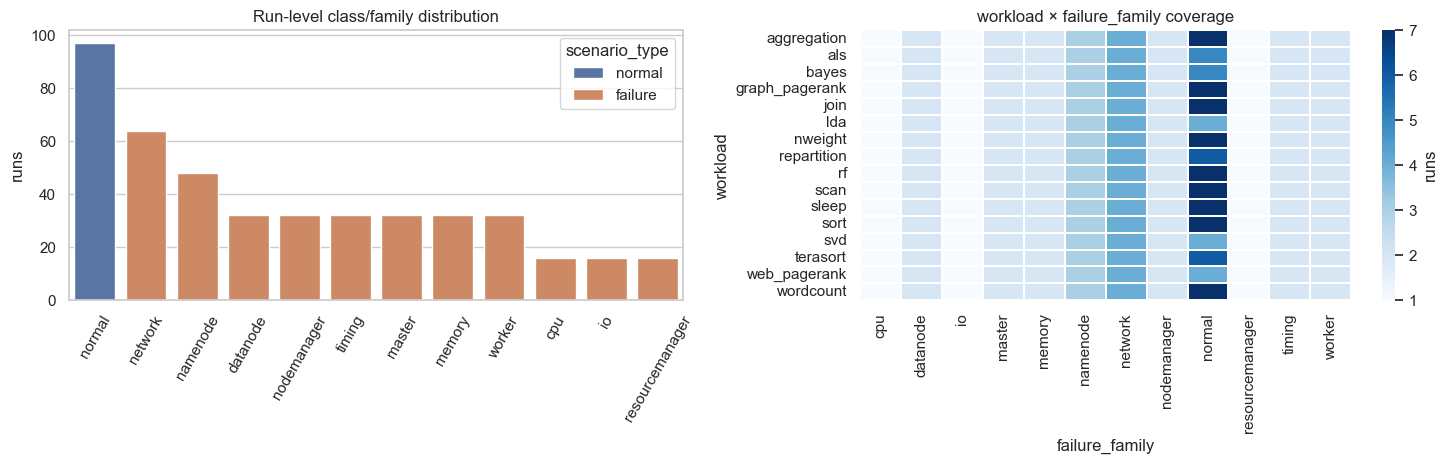


### Локальный вывод раздела

- **Свидетельство:** дисбаланс на run-level и row/window-level. На уровне scenario доля failure runs равна **78.4%**, но в parsed logs положительные события остаются редкими: row-level `Label=1` около **0.195%**.
- **Решение:** `02` должен разделять две разметки: run-level family/type для групп и row/window-level warning/risk target для предсказания.
- **Следствие:** accuracy будет неинформативной; основной метрикой для warning/risk baseline должны быть PR-AUC/precision-recall с group-aware split по workload/scenario/failure_family.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.barplot(data=family_counts.sort_values("runs", ascending=False), x="failure_family", y="runs", hue="scenario_type", ax=axes[0])
axes[0].set_title("Распределение классов и семейств на уровне run")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_xlabel("")

sns.heatmap(family_matrix, cmap="Blues", linewidths=.3, ax=axes[1], cbar_kws={"label": "runs"})
axes[1].set_title("Покрытие workload × failure_family")
axes[1].set_xlabel("failure_family")
axes[1].set_ylabel("workload")
plt.tight_layout()
plt.show()

run_failure_share = float((scenario_inventory_df["scenario_type"] == "failure").mean())
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** дисбаланс на run-level и row/window-level. На уровне scenario доля failure runs равна **{run_failure_share:.1%}**, но в parsed logs положительные события остаются редкими: row-level `Label=1` около **{row_positive_share:.3%}**.
- **Решение:** `02` должен разделять две разметки: run-level family/type для групп и row/window-level warning/risk target для предсказания.
- **Следствие:** accuracy будет неинформативной; основной метрикой для warning/risk baseline должны быть PR-AUC/precision-recall с group-aware split по workload/scenario/failure_family.
"""))

## 4. Логовые шаблоны и компоненты

Шаблоны `Template` и компоненты `Component` дают интерпретируемую текстовую модальность. Этот блок отвечает на вопрос: есть ли частотное ядро шаблонов и какие признаки стоит передавать в `02`.

In [10]:
parsed_non_marker = log_df.loc[~log_df["is_marker"]].copy()

template_counts = parsed_non_marker["Template"].fillna("<NA>").value_counts().rename_axis("Template").reset_index(name="count")
template_counts["share"] = template_counts["count"] / template_counts["count"].sum()
template_counts["cum_share"] = template_counts["share"].cumsum()

top_templates = template_counts.head(20)
component_counts = parsed_non_marker["Component"].fillna("<NA>").value_counts().rename_axis("Component").reset_index(name="count")
component_counts["share"] = component_counts["count"] / component_counts["count"].sum()

top_components = component_counts.head(20)

template_by_label = (
    parsed_non_marker.groupby(["Label", "Template"], dropna=False)
    .size()
    .reset_index(name="count")
    .sort_values(["Label", "count"], ascending=[True, False])
)
top_templates_label = template_by_label.groupby("Label").head(8).reset_index(drop=True)

component_label = parsed_non_marker.pivot_table(index="Component", columns="Label", values="Content", aggfunc="count", fill_value=0)
for col in [0, 1]:
    if col not in component_label.columns:
        component_label[col] = 0
component_label = component_label.rename(columns={0: "label_0", 1: "label_1"})
component_label["total"] = component_label["label_0"] + component_label["label_1"]
component_label["positive_share"] = component_label["label_1"] / component_label["total"].replace(0, np.nan)
component_label = component_label.sort_values(["label_1", "total"], ascending=False).reset_index()

template_length_stats = parsed_non_marker.assign(
    template_chars=parsed_non_marker["Template"].astype(str).str.len(),
    template_tokens=parsed_non_marker["Template"].astype(str).str.split().str.len(),
).groupby("workload", as_index=False).agg(
    templates=("Template", "nunique"),
    median_template_chars=("template_chars", "median"),
    q95_template_chars=("template_chars", lambda s: s.quantile(.95)),
    median_template_tokens=("template_tokens", "median"),
    q95_template_tokens=("template_tokens", lambda s: s.quantile(.95)),
)

display(Markdown("### Наиболее частые шаблоны"))
compact_display(top_templates, n=15)

display(Markdown("### Наиболее частые шаблоны по `Label`"))
compact_display(top_templates_label, n=20)

display(Markdown("### Компоненты с наибольшим числом положительных строк"))
compact_display(component_label.head(20), n=20)

display(Markdown("### Длины и token-статистика шаблонов"))
compact_display(template_length_stats, n=20)

### Наиболее частые шаблоны

,Template,count,share,cum_share
0,Running task <NUM>.<NUM> in stage <NUM>.<NUM> (TID <NUM>),27311,0.107128,0.107128
1,Got assigned task <NUM>,27311,0.107128,0.214257
2,Finished task <NUM>.<NUM> in stage <NUM>.<NUM> (TID <NUM>). <NUM> bytes result sent to driver,26780,0.105046,0.319302
3,Found block <RDD_BRD> locally,21828,0.085621,0.404924
4,Started <NUM> remote fetches in <NUM> ms,13563,0.053201,0.458125
5,"Block <RDD_BRD> stored as values in memory (estimated size <NUM>.<NUM> KiB, free <NUM>.<NUM> MiB)",12256,0.048075,0.506200
6,Getting <NUM> (<NUM>.<NUM> KiB) non-empty blocks including <NUM> (<NUM>.<NUM<*><*><*>local and <NUM> (<NUM>.<NUM> <U...,10263,0.040257,0.546457
7,"Don't have map outputs for shuffle <NUM>, fetching them",9961,0.039072,0.585529
8,Reading broadcast variable <NUM> took <NUM> ms,6462,0.025347,0.610876
9,Started reading broadcast variable <NUM> with <NUM> pieces (estimated total size <NUM>.<NUM> MiB),6462,0.025347,0.636224


Показано 15 строк из 20.

### Наиболее частые шаблоны по `Label`

,Label,Template,count
0,0,Got assigned task <NUM>,27311
1,0,Running task <NUM>.<NUM> in stage <NUM>.<NUM> (TID <NUM>),27311
2,0,Finished task <NUM>.<NUM> in stage <NUM>.<NUM> (TID <NUM>). <NUM> bytes result sent to driver,26780
3,0,Found block <RDD_BRD> locally,21828
4,0,Started <NUM> remote fetches in <NUM> ms,13563
5,0,"Block <RDD_BRD> stored as values in memory (estimated size <NUM>.<NUM> KiB, free <NUM>.<NUM> MiB)",12256
6,0,Getting <NUM> (<NUM>.<NUM> KiB) non-empty blocks including <NUM> (<NUM>.<NUM<*><*><*>local and <NUM> (<NUM>.<NUM> <U...,10263
7,0,"Don't have map outputs for shuffle <NUM>, fetching them",9961
8,1,Failed to get block(s) from worker_host:<NUM>,68
9,1,Abandoning BP-<NUM>-<IP><NUM>:blk_<NUM>_<NUM>,43


### Компоненты с наибольшим числом положительных строк

Label,Component,label_0,label_1,total,positive_share
0,hdfs.DFSClient,1,203,204,0.995098
1,storage.ShuffleBlockFetcherIterator,27126,68,27194,0.002501
2,shuffle.RetryingBlockFetcher,0,42,42,1.000000
3,memory.MemoryStore,24900,33,24933,0.001324
4,executor.CoarseGrainedExecutorBackend,802,27,829,0.032569
5,hdfs.BlockReaderFactory,0,26,26,1.000000
6,yarn.YarnAllocator,2786,14,2800,0.005000
7,util.Utils,2334,13,2347,0.005539
8,executor.YarnCoarseGrainedExecutorBackend,30154,11,30165,0.000365
9,executor.Executor,59445,10,59455,0.000168


### Длины и token-статистика шаблонов

,workload,templates,median_template_chars,q95_template_chars,median_template_tokens,q95_template_tokens
0,aggregation,87,53.0,172.0,6.0,18.0
1,als,84,55.0,176.0,8.0,18.0
2,bayes,82,57.0,176.0,7.0,18.0
3,graph_pagerank,94,55.0,176.0,8.0,18.0
4,join,92,55.0,176.0,7.0,18.0
5,lda,63,46.0,218.0,5.0,18.0
6,repartition,79,57.0,176.0,7.0,14.0
7,rf,71,57.0,176.0,8.0,18.0
8,scan,79,55.0,181.0,6.0,22.0
9,sleep,62,56.0,189.0,5.0,14.0


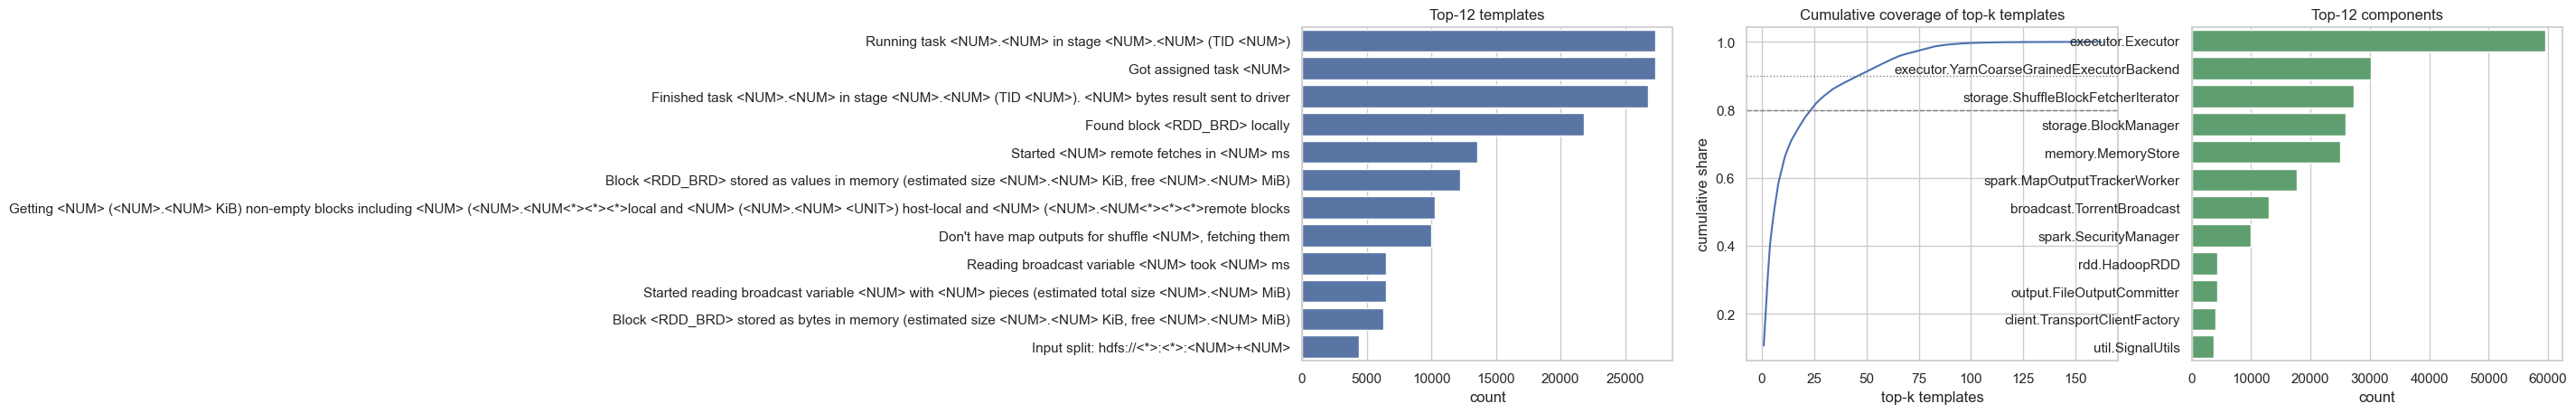


### Локальный вывод раздела

- **Свидетельство:** частотность логовых шаблонов, coverage top-k и компоненты с положительными событиями. 80% строк покрываются примерно **24** наиболее частыми шаблонами, 90% — примерно **46** шаблонами; при этом остаётся редкий хвост.
- **Решение:** для `02` нужны не только counts, но и признаки разнообразия: `unique_templates`, top-template coverage, component counts, error/positive markers, агрегированный `log_text`.
- **Следствие:** частотное ядро повышает устойчивость baseline, а редкий хвост нельзя полностью выбрасывать — именно там могут находиться предсбойные маркеры.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.barplot(data=top_templates.head(12), y="Template", x="count", ax=axes[0], color="#4C72B0")
axes[0].set_title("12 наиболее частых шаблонов")
axes[0].set_ylabel("")

coverage_plot = template_counts.head(200).copy()
sns.lineplot(data=coverage_plot, x=np.arange(1, len(coverage_plot) + 1), y="cum_share", ax=axes[1])
axes[1].set_title("Кумулятивное покрытие top-k шаблонов")
axes[1].set_xlabel("top-k шаблонов")
axes[1].set_ylabel("накопленная доля")
axes[1].axhline(.8, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(.9, color="gray", linestyle=":", linewidth=1)

sns.barplot(data=top_components.head(12), y="Component", x="count", ax=axes[2], color="#55A868")
axes[2].set_title("12 наиболее частых компонентов")
axes[2].set_ylabel("")
plt.tight_layout()
plt.show()

k80 = int((template_counts["cum_share"] < .8).sum() + 1) if len(template_counts) else 0
k90 = int((template_counts["cum_share"] < .9).sum() + 1) if len(template_counts) else 0
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** частотность логовых шаблонов, coverage top-k и компоненты с положительными событиями. 80% строк покрываются примерно **{k80}** наиболее частыми шаблонами, 90% — примерно **{k90}** шаблонами; при этом остаётся редкий хвост.
- **Решение:** для `02` нужны не только counts, но и признаки разнообразия: `unique_templates`, top-template coverage, component counts, error/positive markers, агрегированный `log_text`.
- **Следствие:** частотное ядро повышает устойчивость baseline, а редкий хвост нельзя полностью выбрасывать — именно там могут находиться предсбойные маркеры.
"""))

## 5. Необработанные журналы уровня scenario: provenance и качественные примеры

`mapred_logs/<scenario>.log` — главный источник строгой связи с `scenario`. В отличие от `labeled.csv`, raw files лежат по отдельным runs, поэтому они нужны для alignment с KPI и для качественных фрагментов.

In [12]:
RAW_LOG_RE = re.compile(r"^(?P<date>\d{2}/\d{2}/\d{2})\s+(?P<time>\d{2}:\d{2}:\d{2})\s+(?P<level>[A-Z]+)\s+(?P<component>[^:]+):\s*(?P<message>.*)$")


def parse_raw_log_line(line: str):
    m = RAW_LOG_RE.match(line.strip())
    if not m:
        return None
    ts = pd.to_datetime(f"{m.group('date')} {m.group('time')}", format="%y/%m/%d %H:%M:%S", utc=True, errors="coerce")
    if pd.isna(ts):
        return None
    return ts, m.group("level"), m.group("component"), m.group("message")


def scan_raw_log_file(path: Path):
    total_lines = 0
    event_lines = 0
    first_ts = None
    last_ts = None
    levels = Counter()
    components = Counter()
    examples = []
    try:
        with path.open("r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                total_lines += 1
                parsed = parse_raw_log_line(line)
                if parsed is None:
                    continue
                ts, level, component, message = parsed
                event_lines += 1
                first_ts = ts if first_ts is None or ts < first_ts else first_ts
                last_ts = ts if last_ts is None or ts > last_ts else last_ts
                levels[level] += 1
                components[component] += 1
                if len(examples) < 2:
                    examples.append(line.strip())
    except OSError as exc:
        return {"parse_error": str(exc)}

    duration_sec = (last_ts - first_ts).total_seconds() if first_ts is not None and last_ts is not None else np.nan
    return {
        "total_lines": total_lines,
        "event_lines": event_lines,
        "event_line_share": event_lines / total_lines if total_lines else np.nan,
        "raw_ts_min": first_ts,
        "raw_ts_max": last_ts,
        "raw_duration_sec": duration_sec,
        "top_levels": json.dumps(dict(levels.most_common(3)), ensure_ascii=False),
        "top_components": json.dumps(dict(components.most_common(3)), ensure_ascii=False),
        "example": examples[0] if examples else None,
        "parse_error": None,
    }


def build_raw_log_passport(raw_root: Path):
    rows = []
    for wdir in safe_dirs(raw_root):
        for fp in safe_files(wdir / "mapred_logs", "*.log"):
            meta = scan_raw_log_file(fp)
            rows.append({
                "workload": wdir.name,
                "scenario": fp.stem,
                "run_id": f"{wdir.name}/{fp.stem}",
                "scenario_type": classify_scenario(fp.stem),
                "failure_family": failure_family(fp.stem),
                "path": str(fp.relative_to(ROOT)),
                **meta,
            })
    return pd.DataFrame(rows)


raw_log_passport_df = build_raw_log_passport(RAW_ROOT)
raw_log_summary_df = raw_log_passport_df.groupby(["workload", "scenario_type"], as_index=False).agg(
    raw_logs=("run_id", "nunique"),
    total_lines=("total_lines", "sum"),
    event_lines=("event_lines", "sum"),
    median_duration_min=("raw_duration_sec", lambda s: np.nanmedian(s) / 60),
)

display(Markdown("### Сводка паспорта raw logs"))
compact_display(raw_log_summary_df, n=30)

display(Markdown("### Примеры строк паспорта raw logs"))
compact_display(raw_log_passport_df[["workload", "scenario", "scenario_type", "failure_family", "total_lines", "event_lines", "raw_duration_sec", "top_levels", "example"]], n=12)

### Сводка паспорта raw logs

,workload,scenario_type,raw_logs,total_lines,event_lines,median_duration_min
0,aggregation,failure,22,8599,6050,1.533333
1,aggregation,normal,7,2635,1907,1.183333
2,als,failure,22,73766,71232,0.691667
3,als,normal,5,17984,17464,0.566667
4,bayes,failure,22,16118,13743,0.808333
5,bayes,normal,5,3462,2942,0.983333
6,graph_pagerank,failure,22,34381,29934,0.891667
7,graph_pagerank,normal,7,10760,9416,0.950000
8,join,failure,22,13269,10675,1.875000
9,join,normal,7,4212,3484,1.266667


Показано 30 строк из 31.

### Примеры строк паспорта raw logs

,workload,scenario,scenario_type,failure_family,total_lines,event_lines,raw_duration_sec,top_levels,example
0,aggregation,2nd_namenode_killed,failure,namenode,380,276,70.0,"{""INFO"": 276}",21/10/20 12:23:21 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3580551@master3
1,aggregation,2nd_namenode_suspended,failure,namenode,382,278,73.0,"{""INFO"": 278}",21/10/20 12:21:34 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3558188@master3
2,aggregation,cpu_stress,failure,cpu,380,276,71.0,"{""INFO"": 276}",21/10/20 12:39:44 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3950329@worker2
3,aggregation,datanode_killed,failure,datanode,608,290,126.0,"{""INFO"": 286, ""WARN"": 4}",21/10/20 12:15:05 INFO util.SignalUtils: Registered signal handler for TERM
4,aggregation,datanode_suspended,failure,datanode,382,278,98.0,"{""INFO"": 278}",21/10/20 12:06:53 INFO util.SignalUtils: Registered signal handler for TERM
5,aggregation,io_stress,failure,io,305,207,93.0,"{""INFO"": 207}",21/10/20 12:47:33 INFO util.SignalUtils: Registered signal handler for TERM
6,aggregation,late_sub,failure,timing,380,276,79.0,"{""INFO"": 276}",21/10/20 12:36:10 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3907210@worker2
7,aggregation,lose_package,failure,network,380,276,73.0,"{""INFO"": 276}",21/10/20 12:27:57 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3637673@master3
8,aggregation,master_killed,failure,master,382,278,148.0,"{""INFO"": 278}",21/10/20 12:58:47 INFO util.SignalUtils: Registered signal handler for TERM
9,aggregation,master_suspended,failure,master,380,276,68.0,"{""INFO"": 276}",21/10/20 12:19:46 INFO util.SignalUtils: Registered signal handler for TERM


Показано 12 строк из 442.

In [13]:
example_scenarios = ["normal1", "cpu_stress", "datanode_killed", "net_delay", "memory_stress"]
examples = raw_log_passport_df[raw_log_passport_df["scenario"].isin(example_scenarios)].copy()
examples = examples.sort_values(["scenario", "workload"]).groupby("scenario").head(1)
example_table = examples[["workload", "scenario", "failure_family", "raw_duration_sec", "example"]].copy()
example_table["raw_duration_min"] = example_table["raw_duration_sec"] / 60
example_table = example_table.drop(columns=["raw_duration_sec"])
display(example_table)

display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** raw log-файлы на уровне scenario и примеры строк, которые можно использовать для `log_text` или повторного парсинга. Найдено **{len(raw_log_passport_df):,}** scenario-level raw log файлов; большинство файлов имеют timestamped Spark/YARN строки и сопоставимы с KPI по `workload/scenario`.
- **Решение:** для `02` безопаснее строить run-level log features из `mapred_logs/<scenario>.log`, а workload-level `labeled.csv` использовать как источник словаря шаблонов/компонент и sanity-check разметки.
- **Следствие:** так сохраняется строгий provenance и снижается риск смешать события разных runs внутри одного workload.
"""))

,workload,scenario,failure_family,example,raw_duration_min
2,aggregation,cpu_stress,cpu,21/10/20 12:39:44 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3950329@worker2,1.183333
3,aggregation,datanode_killed,datanode,21/10/20 12:15:05 INFO util.SignalUtils: Registered signal handler for TERM,2.100000
10,aggregation,memory_stress,memory,21/10/20 12:41:34 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3971178@worker2,1.800000
13,aggregation,net_delay,network,21/10/20 12:30:44 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3671912@master3,1.700000
17,aggregation,normal1,normal,21/10/20 11:59:21 INFO executor.CoarseGrainedExecutorBackend: Started daemon with process name: 3465769@worker2,1.166667



### Локальный вывод раздела

- **Свидетельство:** raw log-файлы на уровне scenario и примеры строк, которые можно использовать для `log_text` или повторного парсинга. Найдено **442** scenario-level raw log файлов; большинство файлов имеют timestamped Spark/YARN строки и сопоставимы с KPI по `workload/scenario`.
- **Решение:** для `02` безопаснее строить run-level log features из `mapred_logs/<scenario>.log`, а workload-level `labeled.csv` использовать как источник словаря шаблонов/компонент и sanity-check разметки.
- **Следствие:** так сохраняется строгий provenance и снижается риск смешать события разных runs внутри одного workload.


## 6. Инвентаризация KPI и устойчивый парсинг instrument-файлов

KPI-файлы — не CSV с запятыми, а пробельные таблицы. Внутри файлов встречаются повторные строки заголовка, а некоторые метрики (`iostat`, `netstat`) имеют дополнительное измерение (`Device:`, `IFACE`). Поэтому дальнейший baseline должен использовать series-aware представление: `host + metric + series`.

In [14]:
def build_kpi_file_index(raw_root: Path):
    rows = []
    issues = []
    for wdir in safe_dirs(raw_root):
        workload = wdir.name
        for scenario_dir in safe_dirs(wdir / "kpis"):
            scenario = scenario_dir.name
            instruments_dir = scenario_dir / "instruments"
            if not instruments_dir.exists():
                issues.append({"workload": workload, "scenario": scenario, "host": None, "metric": None, "issue": "missing instruments directory"})
                continue
            for host_dir in safe_dirs(instruments_dir):
                host = host_dir.name
                for fp in safe_files(host_dir):
                    metric = fp.name
                    try:
                        size_bytes = fp.stat().st_size
                    except OSError:
                        size_bytes = np.nan
                    if metric not in EXPECTED_KPI_METRICS:
                        issues.append({"workload": workload, "scenario": scenario, "host": host, "metric": metric, "issue": "unexpected metric file"})
                    rows.append({
                        "workload": workload,
                        "scenario": scenario,
                        "run_id": f"{workload}/{scenario}",
                        "scenario_type": classify_scenario(scenario),
                        "failure_family": failure_family(scenario),
                        "failure_mode": failure_mode(scenario),
                        "host": host,
                        "metric": metric,
                        "path": fp,
                        "rel_path": str(fp.relative_to(ROOT)),
                        "size_bytes": size_bytes,
                        "expected_metric": metric in EXPECTED_KPI_METRICS,
                    })
    return pd.DataFrame(rows), pd.DataFrame(issues)


def extract_timestamp_from_parts(parts):
    if len(parts) < 2:
        return None
    if parts[0] == "HostName" or parts[1] == "TimeStamp":
        return None
    try:
        ts = float(parts[1])
        if ts <= 0:
            return None
        return ts
    except Exception:
        return None


def read_tail_lines(path: Path, chunk_size=65536):
    try:
        with path.open("rb") as f:
            f.seek(0, os.SEEK_END)
            end = f.tell()
            if end == 0:
                return []
            offset = max(0, end - chunk_size)
            f.seek(offset)
            data = f.read().decode("utf-8", errors="ignore")
        lines = data.splitlines()
        if offset > 0 and lines:
            lines = lines[1:]
        return lines
    except OSError:
        return []


def kpi_file_metadata(path: Path, max_ts_sample=KPI_HEAD_TS_SAMPLE):
    header_cols = None
    header_repeats_head = 0
    sample_ts = []
    first_data_line_parts = None
    first_data_line_len = None
    lines_seen = 0
    try:
        with path.open("r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                lines_seen += 1
                stripped = line.strip()
                if not stripped:
                    continue
                parts = stripped.split()
                if parts and parts[0] == "HostName":
                    header_repeats_head += 1
                    if header_cols is None:
                        header_cols = parts
                    continue
                ts = extract_timestamp_from_parts(parts)
                if ts is None:
                    continue
                if first_data_line_parts is None:
                    first_data_line_parts = parts
                    first_data_line_len = len(line.encode("utf-8", errors="ignore"))
                sample_ts.append(ts)
                if len(sample_ts) >= max_ts_sample:
                    break
    except OSError as exc:
        return {"metadata_error": str(exc)}

    last_ts = None
    for line in reversed(read_tail_lines(path)):
        ts = extract_timestamp_from_parts(line.strip().split())
        if ts is not None:
            last_ts = ts
            break

    first_ts = sample_ts[0] if sample_ts else np.nan
    sample_unique = np.array(sorted(set(sample_ts)))
    if len(sample_unique) > 1:
        diffs = np.diff(sample_unique)
        diffs = diffs[diffs > 0]
        median_interval = float(np.median(diffs)) if len(diffs) else np.nan
    else:
        median_interval = np.nan

    dim_cols = []
    if header_cols:
        for dim in ["Device:", "IFACE", "DEV", "Filesystem"]:
            if dim in header_cols:
                dim_cols.append(dim)
        value_cols = [c for c in header_cols if c not in {"HostName", "TimeStamp", *dim_cols}]
    else:
        value_cols = []

    duration_sec = float(last_ts - first_ts) if pd.notna(first_ts) and last_ts is not None else np.nan
    approx_rows = np.nan
    try:
        if first_data_line_len and first_data_line_len > 0:
            approx_rows = int(path.stat().st_size / first_data_line_len)
    except OSError:
        pass

    return {
        "header_cols": "|".join(header_cols) if header_cols else None,
        "value_columns": "|".join(value_cols),
        "value_column_count": len(value_cols),
        "dimension_columns": "|".join(dim_cols),
        "header_repeats_in_head_sample": header_repeats_head,
        "first_ts": first_ts,
        "last_ts": last_ts,
        "timestamp_sample_n": len(sample_ts),
        "sample_median_interval_sec": median_interval,
        "duration_sec": duration_sec,
        "approx_rows_by_size": approx_rows,
        "metadata_error": None,
    }


kpi_file_index_df, kpi_file_issues_df = build_kpi_file_index(RAW_ROOT)
# Lightweight metadata scan over all KPI files. It reads only head samples and tail chunks, not full values.
metadata_rows = []
for rec in kpi_file_index_df.itertuples(index=False):
    metadata_rows.append(kpi_file_metadata(rec.path))
kpi_meta_df = pd.concat([kpi_file_index_df.reset_index(drop=True), pd.DataFrame(metadata_rows)], axis=1)
kpi_meta_df["first_dt"] = pd.to_datetime(kpi_meta_df["first_ts"], unit="s", utc=True, errors="coerce")
kpi_meta_df["last_dt"] = pd.to_datetime(kpi_meta_df["last_ts"], unit="s", utc=True, errors="coerce")
kpi_meta_df["duration_min"] = kpi_meta_df["duration_sec"] / 60
kpi_meta_df["size_mb"] = kpi_meta_df["size_bytes"] / 1024 / 1024

kpi_availability_by_run = kpi_meta_df.groupby(["workload", "scenario", "run_id", "scenario_type", "failure_family"], as_index=False).agg(
    hosts=("host", "nunique"),
    metrics=("metric", "nunique"),
    files=("metric", "size"),
    expected_files=("expected_metric", "sum"),
    size_mb=("size_mb", "sum"),
    kpi_ts_min=("first_dt", "min"),
    kpi_ts_max=("last_dt", "max"),
    median_file_interval_sec=("sample_median_interval_sec", "median"),
    median_file_duration_min=("duration_min", "median"),
)
kpi_availability_by_run["kpi_run_duration_min"] = (kpi_availability_by_run["kpi_ts_max"] - kpi_availability_by_run["kpi_ts_min"]).dt.total_seconds() / 60

metric_rows = kpi_meta_df.groupby("metric", as_index=False).agg(
    files=("metric", "size"),
    runs=("run_id", "nunique"),
    hosts=("host", "nunique"),
    total_size_mb=("size_mb", "sum"),
    median_duration_min=("duration_min", "median"),
    median_interval_sec=("sample_median_interval_sec", "median"),
    median_value_columns=("value_column_count", "median"),
    metadata_errors=("metadata_error", lambda s: s.notna().sum()),
).sort_values("files", ascending=False)

host_rows = kpi_availability_by_run.groupby("workload", as_index=False).agg(
    runs_with_kpi=("run_id", "nunique"),
    median_hosts=("hosts", "median"),
    min_hosts=("hosts", "min"),
    max_hosts=("hosts", "max"),
    median_metrics=("metrics", "median"),
    median_kpi_duration_min=("kpi_run_duration_min", "median"),
)

display(Markdown("### Сводка индекса KPI-файлов"))
display(pd.DataFrame({
    "kpi_files": [len(kpi_meta_df)],
    "total_size": [format_bytes(kpi_meta_df["size_bytes"].sum())],
    "runs_with_kpi": [kpi_meta_df["run_id"].nunique()],
    "unexpected_metric_files": [int((~kpi_meta_df["expected_metric"]).sum())],
}))

display(Markdown("### Метрики в KPI-каталогах"))
display(metric_rows)

display(Markdown("### Hosts и длительность KPI по workload"))
compact_display(host_rows, n=20)

display(Markdown("### Проблемы парсинга и инвентаризации KPI"))
compact_display(kpi_file_issues_df, n=20)

### Сводка индекса KPI-файлов

,kpi_files,total_size,runs_with_kpi,unexpected_metric_files
0,16093,3.6 GB,447,1


### Метрики в KPI-каталогах

,metric,files,runs,hosts,total_size_mb,median_duration_min,median_interval_sec,median_value_columns,metadata_errors
0,cpustat,2682,447,6,1476.757318,1.950000,1.0,6.0,0
1,iostat,2682,447,6,1755.856937,1.966667,1.0,15.0,0
2,jvms,2682,447,6,15.227473,1.966667,1.0,2.0,0
3,memstat,2682,447,6,273.640145,1.933333,1.0,25.0,0
4,netstat,2682,447,6,138.253094,1.950000,1.0,8.0,0
6,vmstat,2682,447,6,69.104121,1.966667,1.0,17.0,0
5,pgid,1,1,1,0.000006,NaN,NaN,0.0,0


### Hosts и длительность KPI по workload

,workload,runs_with_kpi,median_hosts,min_hosts,max_hosts,median_metrics,median_kpi_duration_min
0,aggregation,29,6.0,6,6,6.0,2.000000
1,als,26,6.0,6,6,6.0,1.133333
2,bayes,26,6.0,6,6,6.0,1.400000
3,graph_pagerank,29,6.0,6,6,6.0,1.433333
4,join,29,6.0,6,6,6.0,1.983333
5,lda,26,6.0,6,6,6.0,0.791667
6,nweight,29,6.0,6,6,6.0,25.016667
7,repartition,28,6.0,6,6,6.0,2.341667
8,rf,29,6.0,6,6,6.0,1.250000
9,scan,29,6.0,6,6,6.0,1.833333


### Проблемы парсинга и инвентаризации KPI

,workload,scenario,host,metric,issue
0,web_pagerank,2nd_namenode_killed,worker3,pgid,unexpected metric file


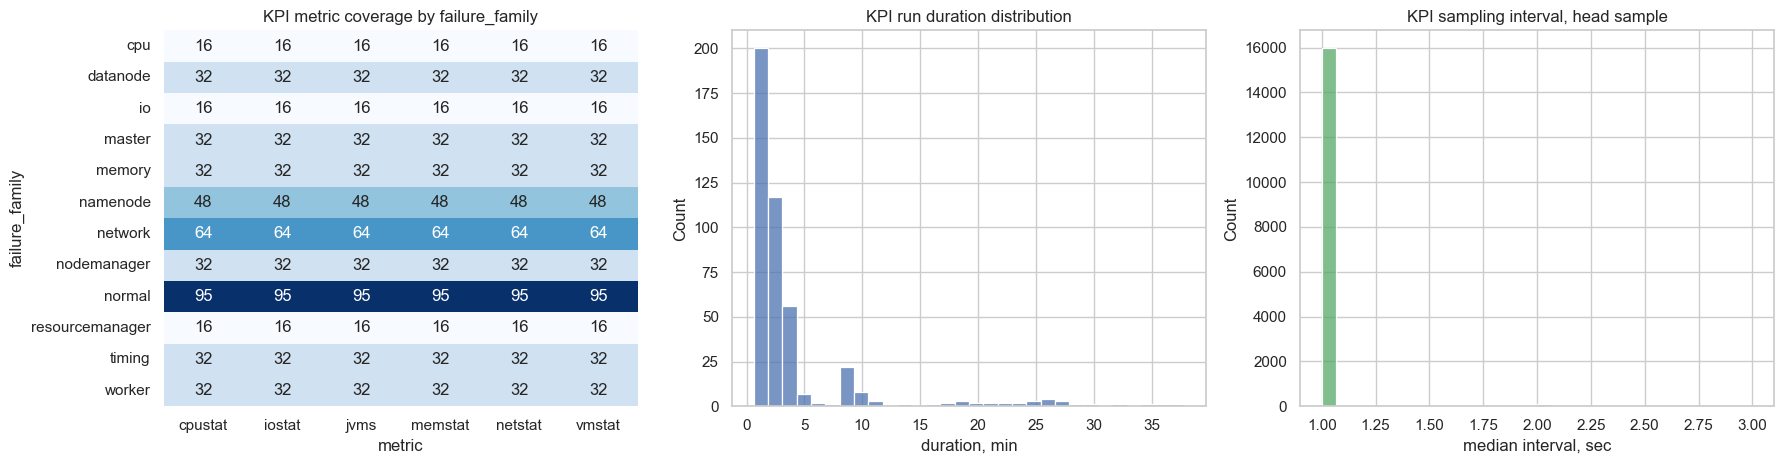


### Локальный вывод раздела

- **Свидетельство:** availability KPI по метрикам, длительности runs и частота timestamp в instrument-файлах. Найдено **16,093** instrument-файлов общим объёмом около **3.6 GB**; медианный sampling interval по head-sample равен примерно **1.0 sec**, медианная KPI-длительность run — **2.0 min**.
- **Решение:** KPI-модальность достаточно регулярна для micro-window признаков, но неоднородна по host/metric/series и требует собственного парсера.
- **Следствие:** в `02` нельзя читать KPI как один плоский CSV; нужен series-aware loader с обработкой повторных headers и отдельными признаками availability/recency.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
coverage_counts = kpi_meta_df[kpi_meta_df["expected_metric"]].pivot_table(
    index="failure_family", columns="metric", values="run_id", aggfunc="nunique", fill_value=0
)
sns.heatmap(coverage_counts, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Покрытие KPI-метрик по failure_family")
axes[0].set_xlabel("метрика")
axes[0].set_ylabel("failure_family")

sns.histplot(kpi_availability_by_run["kpi_run_duration_min"].dropna(), bins=30, ax=axes[1], color="#4C72B0")
axes[1].set_title("Распределение длительности KPI на уровне run")
axes[1].set_xlabel("длительность, мин")

interval_data = kpi_meta_df.loc[kpi_meta_df["sample_median_interval_sec"].notna() & kpi_meta_df["expected_metric"], "sample_median_interval_sec"]
sns.histplot(interval_data, bins=30, ax=axes[2], color="#55A868")
axes[2].set_title("Интервал дискретизации KPI, head-sample")
axes[2].set_xlabel("медианный интервал, с")
plt.tight_layout()
plt.show()

median_interval = float(interval_data.median()) if len(interval_data) else np.nan
median_duration = float(kpi_availability_by_run["kpi_run_duration_min"].median()) if len(kpi_availability_by_run) else np.nan
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** availability KPI по metricм, длительности runs и частота timestamp в instrument-файлах. Найдено **{len(kpi_meta_df):,}** instrument-файлов общим объёмом около **{format_bytes(kpi_meta_df['size_bytes'].sum())}**; медианный sampling interval по head-sample равен примерно **{median_interval:.1f} sec**, медианная KPI-длительность run — **{median_duration:.1f} min**.
- **Решение:** KPI-модальность достаточно регулярна для micro-window признаков, но неоднородна по host/metric/series и требует собственного парсера.
- **Следствие:** в `02` нельзя читать KPI как один плоский CSV; нужен series-aware loader с обработкой повторных headers и отдельными признаками availability/recency.
"""))

## 7. Статистический профиль KPI на value-level выборке

Полный value-level разбор всех KPI-файлов в `01` был бы тяжёлым ETL. Для исследовательской цели достаточно сбалансированной выборки по `metric × failure_family`, чтобы проверить шкалы, нули, вариативность и формат wide→long.

In [16]:
def parse_instrument_file(path: Path, workload: str, scenario: str, host: str, metric: str):
    try:
        df = pd.read_csv(path, sep=r"\s+", engine="python")
    except Exception as exc:
        return pd.DataFrame(), {"path": str(path), "issue": f"read_csv failed: {exc}"}

    if "TimeStamp" not in df.columns or "HostName" not in df.columns:
        return pd.DataFrame(), {"path": str(path), "issue": "missing HostName/TimeStamp columns"}

    # Drop repeated headers that appear as data rows.
    df = df[df["TimeStamp"].astype(str) != "TimeStamp"].copy()
    df["TimeStamp"] = pd.to_numeric(df["TimeStamp"], errors="coerce")
    df = df[df["TimeStamp"].notna()].copy()
    if df.empty:
        return pd.DataFrame(), {"path": str(path), "issue": "no valid timestamp rows"}

    dim_cols = [c for c in ["Device:", "IFACE", "DEV", "Filesystem"] if c in df.columns]
    if not dim_cols and df.duplicated(subset=["TimeStamp"]).any():
        # cpustat often contains several rows per timestamp without an explicit CPU id.
        # Preserve information as a synthetic slot; later pipeline may aggregate it.
        df["_slot"] = df.groupby("TimeStamp").cumcount().astype(str)
        dim_cols = ["_slot"]

    id_cols = ["HostName", "TimeStamp"] + dim_cols
    value_cols = [c for c in df.columns if c not in id_cols]
    for c in value_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    value_cols = [c for c in value_cols if df[c].notna().any()]
    if not value_cols:
        return pd.DataFrame(), {"path": str(path), "issue": "no numeric value columns"}

    long = df.melt(id_vars=id_cols, value_vars=value_cols, var_name="raw_series", value_name="value")
    long = long[long["value"].notna()].copy()
    if dim_cols:
        dim_part = long[dim_cols].astype(str).agg("__".join, axis=1)
        long["series"] = dim_part + "__" + long["raw_series"].astype(str)
    else:
        long["series"] = long["raw_series"].astype(str)
    long["timestamp"] = pd.to_datetime(long["TimeStamp"], unit="s", utc=True, errors="coerce")
    long["workload"] = workload
    long["scenario"] = scenario
    long["run_id"] = f"{workload}/{scenario}"
    long["scenario_type"] = classify_scenario(scenario)
    long["failure_family"] = failure_family(scenario)
    long["host"] = host
    long["metric"] = metric
    long["observed_hostname"] = long["HostName"].astype(str)
    keep = ["workload", "scenario", "run_id", "scenario_type", "failure_family", "host", "observed_hostname", "metric", "series", "timestamp", "value"]
    return long[keep], None


def select_kpi_value_sample(kpi_meta_df: pd.DataFrame, per_metric_family=1, max_files=96):
    candidates = kpi_meta_df[
        kpi_meta_df["expected_metric"]
        & kpi_meta_df["first_dt"].notna()
        & kpi_meta_df["last_dt"].notna()
        & (kpi_meta_df["size_bytes"] > 0)
    ].copy()
    candidates = candidates.sort_values(["metric", "failure_family", "workload", "scenario", "host"])
    sampled = candidates.groupby(["metric", "failure_family"], group_keys=False).head(per_metric_family)
    if len(sampled) > max_files:
        sampled = sampled.head(max_files)
    return sampled.reset_index(drop=True)


kpi_value_sample_files_df = select_kpi_value_sample(kpi_meta_df, KPI_VALUE_SAMPLE_PER_METRIC_FAMILY, KPI_VALUE_SAMPLE_MAX_FILES)
long_parts = []
parse_issues = []
for rec in kpi_value_sample_files_df.itertuples(index=False):
    long, issue = parse_instrument_file(rec.path, rec.workload, rec.scenario, rec.host, rec.metric)
    if issue:
        parse_issues.append({**issue, "workload": rec.workload, "scenario": rec.scenario, "host": rec.host, "metric": rec.metric})
    if len(long):
        long_parts.append(long)

kpi_sample_long_df = pd.concat(long_parts, ignore_index=True) if long_parts else pd.DataFrame()
kpi_value_parse_issues_df = pd.DataFrame(parse_issues)

if len(kpi_sample_long_df):
    kpi_series_stats_df = kpi_sample_long_df.groupby(["metric", "series"], as_index=False).agg(
        count=("value", "size"),
        runs=("run_id", "nunique"),
        hosts=("host", "nunique"),
        median=("value", "median"),
        q05=("value", lambda s: s.quantile(.05)),
        q95=("value", lambda s: s.quantile(.95)),
        zero_share=("value", lambda s: float((s == 0).mean())),
    )
    kpi_series_stats_df["iqr90"] = kpi_series_stats_df["q95"] - kpi_series_stats_df["q05"]
    top_variable_kpi_df = kpi_series_stats_df.sort_values("iqr90", ascending=False).head(20)
    zero_heavy_kpi_df = kpi_series_stats_df.sort_values(["zero_share", "count"], ascending=False).head(20)
else:
    kpi_series_stats_df = pd.DataFrame()
    top_variable_kpi_df = pd.DataFrame()
    zero_heavy_kpi_df = pd.DataFrame()

sample_summary_df = pd.DataFrame({
    "sample_files": [len(kpi_value_sample_files_df)],
    "sample_long_rows": [len(kpi_sample_long_df)],
    "sample_runs": [kpi_sample_long_df["run_id"].nunique() if len(kpi_sample_long_df) else 0],
    "sample_metrics": [kpi_sample_long_df["metric"].nunique() if len(kpi_sample_long_df) else 0],
    "parse_issues": [len(kpi_value_parse_issues_df)],
})

display(Markdown("### Сводка value-level выборки KPI"))
display(sample_summary_df)

display(Markdown("### Наиболее вариативные KPI series"))
compact_display(top_variable_kpi_df, n=15)

display(Markdown("### KPI series с высокой долей нулей"))
compact_display(zero_heavy_kpi_df, n=15)

display(Markdown("### Проблемы value-level парсинга"))
compact_display(kpi_value_parse_issues_df, n=15)

### Сводка value-level выборки KPI

,sample_files,sample_long_rows,sample_runs,sample_metrics,parse_issues
0,72,876965,12,6,0


### Наиболее вариативные KPI series

,metric,series,count,runs,hosts,median,q05,q95,zero_share,iqr90
762,memstat,kbmemfree,1545,12,1,5847568.0,1981475.2,13787836.0,0.0,11806360.8
763,memstat,kbmemused,1545,12,1,26904180.0,18963912.0,30770272.8,0.0,11806360.8
796,vmstat,free,1592,12,1,5861392.0,2007221.4,13785598.2,0.0,11778376.8
761,memstat,kbinact,1545,12,1,21990828.0,15012379.2,25889587.2,0.0,10877208.0
794,vmstat,cache,1592,12,1,16037968.0,7537793.6,17766127.0,0.0,10228333.4
758,memstat,kbcached,1545,12,1,15162308.0,6790717.6,16876951.2,0.0,10086233.6
759,memstat,kbcommit,1545,12,1,30076576.0,26985479.2,34937943.2,0.0,7952464.0
756,memstat,kbavail,1545,12,1,21485576.0,19188063.2,22771125.6,0.0,3583062.4
760,memstat,kbdirty,1545,12,1,124520.0,4517.6,1528249.6,0.0,1523732.0
755,memstat,kbactive,1545,12,1,2829192.0,2132751.2,3043511.2,0.0,910760.0


Показано 15 строк из 20.

### KPI series с высокой долей нулей

,metric,series,count,runs,hosts,median,q05,q95,zero_share,iqr90
802,vmstat,st,1592,12,1,0.0,0.0,0.0,1.0,0.0
492,iostat,loop0__%rrqm,1570,12,1,0.0,0.0,0.0,1.0,0.0
493,iostat,loop0__%util,1570,12,1,0.0,0.0,0.0,1.0,0.0
494,iostat,loop0__%wrqm,1570,12,1,0.0,0.0,0.0,1.0,0.0
495,iostat,loop0__aqu-sz,1570,12,1,0.0,0.0,0.0,1.0,0.0
496,iostat,loop0__r/s,1570,12,1,0.0,0.0,0.0,1.0,0.0
499,iostat,loop0__rkB/s,1570,12,1,0.0,0.0,0.0,1.0,0.0
500,iostat,loop0__rrqm/s,1570,12,1,0.0,0.0,0.0,1.0,0.0
502,iostat,loop0__w/s,1570,12,1,0.0,0.0,0.0,1.0,0.0
503,iostat,loop0__w_await,1570,12,1,0.0,0.0,0.0,1.0,0.0


Показано 15 строк из 20.

### Проблемы value-level парсинга

""


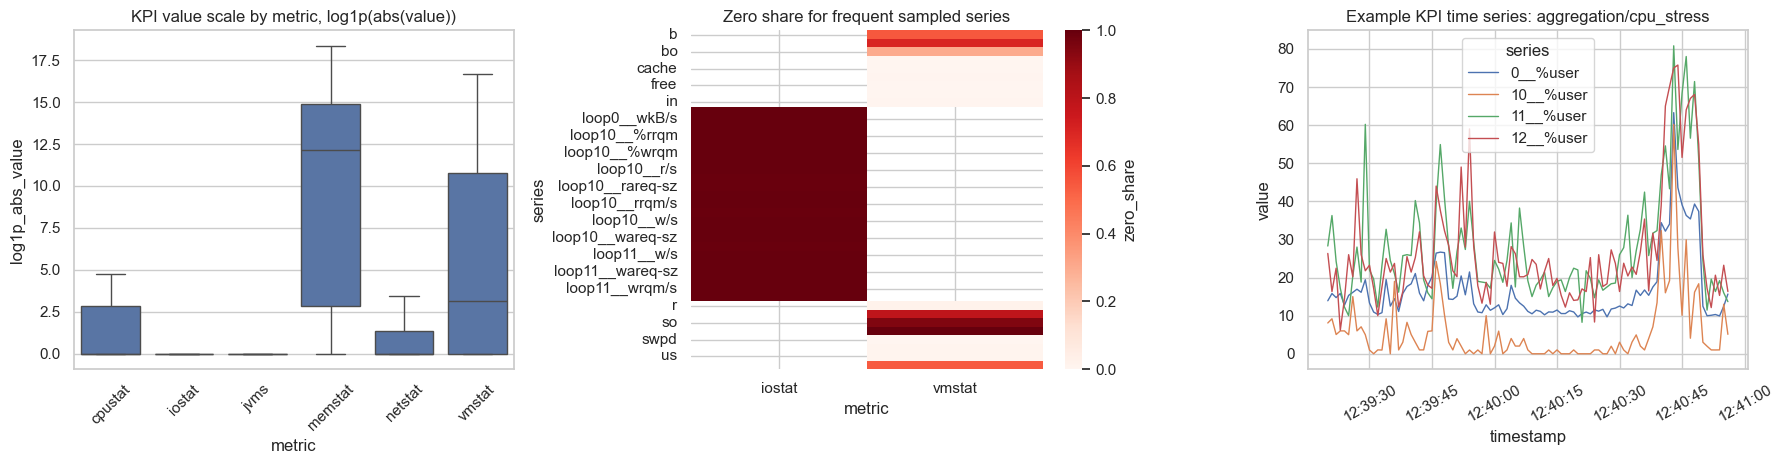


### Локальный вывод раздела

- **Свидетельство:** value-level профиль KPI на сбалансированной выборке instrument-файлов. Шкалы метрик существенно различаются; часть series почти всегда равна нулю, а часть имеет широкий диапазон значений.
- **Решение:** единая ненормированная шкала KPI некорректна; в `02` нужна нормализация внутри `host/metric/series` и признаки availability/recency.
- **Следствие:** без series-aware нормализации модель будет учить масштаб метрики вместо изменения состояния run.


In [17]:
if len(kpi_sample_long_df):
    plot_df = kpi_sample_long_df.copy()
    plot_df["log1p_abs_value"] = np.log1p(np.abs(plot_df["value"]))
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    sns.boxplot(data=plot_df, x="metric", y="log1p_abs_value", ax=axes[0], showfliers=False)
    axes[0].set_title("Шкала значений KPI по метрикам, log1p(abs(value))")
    axes[0].tick_params(axis="x", rotation=45)

    zero_pivot = kpi_series_stats_df.sort_values("count", ascending=False).head(40).pivot_table(index="series", columns="metric", values="zero_share", aggfunc="mean")
    sns.heatmap(zero_pivot, cmap="Reds", ax=axes[1], cbar_kws={"label": "zero_share"})
    axes[1].set_title("Доля нулей для частых sampled series")
    axes[1].set_xlabel("метрика")
    axes[1].set_ylabel("series")

    # Representative time series: cpustat %user if available, otherwise any variable series.
    candidate = kpi_sample_long_df[(kpi_sample_long_df["metric"] == "cpustat") & (kpi_sample_long_df["series"].str.contains("%user", regex=False, na=False))]
    if candidate.empty:
        top_key = top_variable_kpi_df[["metric", "series"]].head(1)
        if len(top_key):
            candidate = kpi_sample_long_df.merge(top_key, on=["metric", "series"], how="inner")
    if not candidate.empty:
        one_run = candidate["run_id"].iloc[0]
        ts_plot = candidate[candidate["run_id"] == one_run].groupby(["timestamp", "metric", "series"], as_index=False)["value"].mean()
        # If synthetic cpustat slots create many series, plot only first few.
        selected_series = ts_plot["series"].drop_duplicates().head(4).tolist()
        ts_plot = ts_plot[ts_plot["series"].isin(selected_series)]
        sns.lineplot(data=ts_plot, x="timestamp", y="value", hue="series", ax=axes[2], linewidth=1)
        axes[2].set_title(f"Пример временного ряда KPI: {one_run}")
        axes[2].tick_params(axis="x", rotation=30)
    else:
        axes[2].axis("off")
        axes[2].text(.5, .5, "No KPI sample for time-series plot", ha="center")
    plt.tight_layout()
    plt.show()

    display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** value-level профиль KPI на сбалансированной выборке instrument-файлов. Шкалы метрик существенно различаются; часть series почти всегда равна нулю, а часть имеет широкий диапазон значений.
- **Решение:** единая ненормированная шкала KPI некорректна; в `02` нужна нормализация внутри `host/metric/series` и признаки availability/recency.
- **Следствие:** без series-aware нормализации модель будет учить масштаб метрики вместо изменения состояния run.
"""))
else:
    display(Markdown("KPI value-level sample is empty; см. parse issues выше."))

## 8. Временное разрешение и обоснование multi-rate окон

Следующий notebook должен выбирать окна не произвольно, а на основании длительности runs и sampling interval. Здесь сравниваются candidate windows: `10s`, `30s`, `1min`, `5min`.

In [18]:
# Run spans from raw logs and KPI metadata.
raw_run_span_df = raw_log_passport_df.groupby(["workload", "scenario", "run_id"], as_index=False).agg(
    raw_ts_min=("raw_ts_min", "min"),
    raw_ts_max=("raw_ts_max", "max"),
    raw_duration_sec=("raw_duration_sec", "max"),
    raw_event_lines=("event_lines", "sum"),
)
kpi_run_span_df = kpi_availability_by_run[["workload", "scenario", "run_id", "kpi_ts_min", "kpi_ts_max", "kpi_run_duration_min", "median_file_interval_sec"]].copy()
kpi_run_span_df["kpi_duration_sec"] = kpi_run_span_df["kpi_run_duration_min"] * 60

run_span_df = scenario_inventory_df[["workload", "scenario", "run_id", "scenario_type", "failure_family", "strict_path_pair"]].merge(
    raw_run_span_df, on=["workload", "scenario", "run_id"], how="left"
).merge(
    kpi_run_span_df, on=["workload", "scenario", "run_id"], how="left"
)
run_span_df["combined_start"] = run_span_df[["raw_ts_min", "kpi_ts_min"]].min(axis=1)
run_span_df["combined_end"] = run_span_df[["raw_ts_max", "kpi_ts_max"]].max(axis=1)
run_span_df["combined_duration_sec"] = (run_span_df["combined_end"] - run_span_df["combined_start"]).dt.total_seconds()
run_span_df["best_duration_sec"] = run_span_df[["raw_duration_sec", "kpi_duration_sec", "combined_duration_sec"]].max(axis=1)
run_span_df["best_duration_min"] = run_span_df["best_duration_sec"] / 60

window_report_rows = []
for window_sec in WINDOW_SECONDS:
    windows = np.ceil(run_span_df["best_duration_sec"].clip(lower=0) / window_sec)
    window_report_rows.append({
        "window_sec": window_sec,
        "window_label": f"{window_sec}s" if window_sec < 60 else f"{window_sec // 60}min",
        "median_windows_per_run": float(np.nanmedian(windows)),
        "q05_windows_per_run": float(np.nanpercentile(windows.dropna(), 5)) if windows.notna().any() else np.nan,
        "q95_windows_per_run": float(np.nanpercentile(windows.dropna(), 95)) if windows.notna().any() else np.nan,
        "share_collapsed_to_one_window": float((windows <= 1).mean()),
        "runs_with_duration": int(run_span_df["best_duration_sec"].notna().sum()),
    })
window_resolution_report_df = pd.DataFrame(window_report_rows)

expected_rows_per_run_df = run_span_df[["workload", "scenario", "run_id", "scenario_type", "failure_family", "best_duration_min", "raw_duration_sec", "kpi_duration_sec", "median_file_interval_sec"]].copy()
for window_sec in WINDOW_SECONDS:
    expected_rows_per_run_df[f"windows_{window_sec}s"] = np.ceil(expected_rows_per_run_df["best_duration_min"].fillna(0) * 60 / window_sec).astype(int)

display(Markdown("### Отчёт по оконному разрешению"))
display(window_resolution_report_df)

display(Markdown("### Ожидаемое число строк на run: примеры"))
compact_display(expected_rows_per_run_df.sort_values("best_duration_min", ascending=False), n=15)

### Отчёт по оконному разрешению

,window_sec,window_label,median_windows_per_run,q05_windows_per_run,q95_windows_per_run,share_collapsed_to_one_window,runs_with_duration
0,10,10s,12.0,5.0,117.0,0.000000,449
1,30,30s,4.0,2.0,39.0,0.000000,449
2,60,1min,2.0,1.0,20.0,0.129176,449
3,300,5min,1.0,1.0,4.0,0.848552,449


### Ожидаемое число строк на run: примеры

,workload,scenario,run_id,scenario_type,failure_family,best_duration_min,raw_duration_sec,kpi_duration_sec,median_file_interval_sec,windows_10s,windows_30s,windows_60s,windows_300s
191,nweight,resourcemanager_suspended,nweight/resourcemanager_suspended,failure,resourcemanager,37.833333,2041.0,2270.0,1.0,227,76,38,8
172,nweight,io_stress,nweight/io_stress,failure,io,35.566667,2007.0,2134.0,1.0,214,72,36,8
192,nweight,slow_stress,nweight/slow_stress,failure,timing,34.150000,1943.0,2049.0,1.0,205,69,35,7
182,nweight,nodemanager_killed,nweight/nodemanager_killed,failure,nodemanager,31.733333,1880.0,1904.0,1.0,191,64,32,7
179,nweight,namenode_suspended,nweight/namenode_suspended,failure,namenode,30.366667,1795.0,1822.0,1.0,183,61,31,7
189,nweight,normal6,nweight/normal6,normal,normal,28.166667,NaN,1690.0,1.0,169,57,29,6
190,nweight,normal7,nweight/normal7,normal,normal,27.450000,NaN,1647.0,1.0,165,55,28,6
180,nweight,net_delay,nweight/net_delay,failure,network,27.000000,NaN,1620.0,1.0,162,54,27,6
168,nweight,2nd_namenode_suspended,nweight/2nd_namenode_suspended,failure,namenode,26.783333,1585.0,1607.0,1.0,161,54,27,6
193,nweight,vm_stress,nweight/vm_stress,failure,memory,26.416667,1494.0,1584.0,1.0,159,53,27,6


Показано 15 строк из 449.

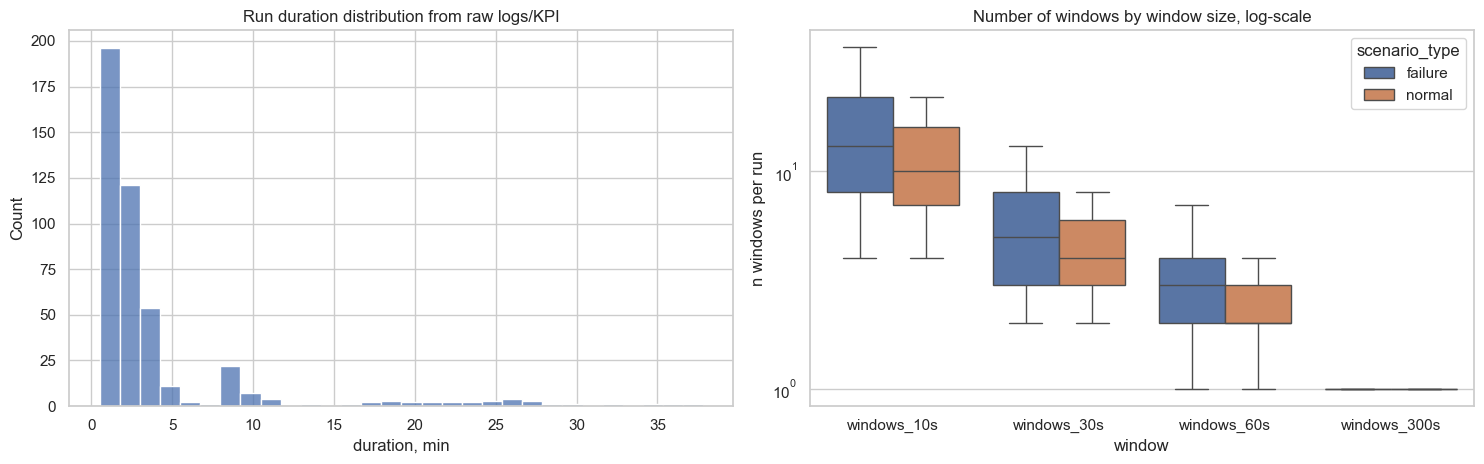

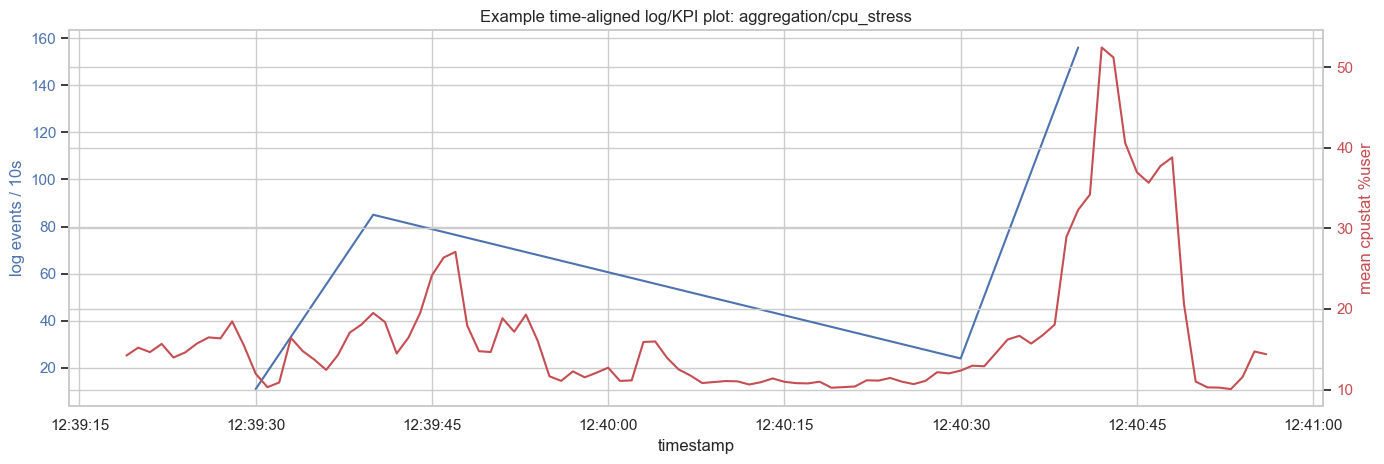


### Локальный вывод раздела

- **Свидетельство:** длительности runs, ожидаемое число окон и пример совмещения log/KPI по времени. Короткие KPI intervals поддерживают micro-windows **10s/30s**, а log-контекст целесообразно агрегировать крупнее — **1min/5min**.
- **Решение:** в `02` стоит тестировать multi-rate схему: macro log context 1–5 min + micro KPI/log windows 10–30 sec.
- **Следствие:** единое окно для обеих модальностей либо размоет KPI-динамику, либо сделает логовые признаки слишком шумными.


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(run_span_df["best_duration_min"].dropna(), bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("Распределение длительности run по raw logs/KPI")
axes[0].set_xlabel("длительность, мин")

windows_long = expected_rows_per_run_df.melt(
    id_vars=["run_id", "scenario_type"],
    value_vars=[f"windows_{w}s" for w in WINDOW_SECONDS],
    var_name="window", value_name="n_windows",
)
sns.boxplot(data=windows_long, x="window", y="n_windows", hue="scenario_type", ax=axes[1], showfliers=False)
axes[1].set_yscale("log")
axes[1].set_title("Число окон по размеру окна, логарифмическая шкала")
axes[1].set_xlabel("размер окна")
axes[1].set_ylabel("число окон на run")
plt.tight_layout()
plt.show()

# Example time-aligned plot for one failure run with both modalities.
def extract_raw_event_times(path: Path):
    times = []
    try:
        with path.open("r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                parsed = parse_raw_log_line(line)
                if parsed:
                    times.append(parsed[0])
    except OSError:
        pass
    return pd.Series(times, dtype="datetime64[ns, UTC]")

example_run = scenario_inventory_df[(scenario_inventory_df["strict_path_pair"]) & (scenario_inventory_df["scenario"] == "cpu_stress")].head(1)
if len(example_run):
    w = example_run.iloc[0]["workload"]
    sc = example_run.iloc[0]["scenario"]
    raw_path = RAW_ROOT / w / "mapred_logs" / f"{sc}.log"
    event_times = extract_raw_event_times(raw_path)
    log_counts = pd.DataFrame({"timestamp": event_times})
    if len(log_counts):
        log_counts["window_10s"] = log_counts["timestamp"].dt.floor("10s")
        log_counts = log_counts.groupby("window_10s", as_index=False).size().rename(columns={"size": "log_events_10s"})
    cpustat_paths = list((RAW_ROOT / w / "kpis" / sc / "instruments").glob("*/cpustat"))[:3]
    kpi_parts = []
    for p in cpustat_paths:
        host = p.parent.name
        long, _ = parse_instrument_file(p, w, sc, host, "cpustat")
        if len(long):
            kpi_parts.append(long)
    if kpi_parts:
        kpi_example = pd.concat(kpi_parts, ignore_index=True)
        kpi_example = kpi_example[kpi_example["series"].str.contains("%user", regex=False, na=False)]
        kpi_example = kpi_example.groupby("timestamp", as_index=False)["value"].mean().rename(columns={"value": "mean_cpustat_user"})
    else:
        kpi_example = pd.DataFrame()

    fig, ax1 = plt.subplots(figsize=(14, 4.8))
    if len(log_counts):
        ax1.plot(log_counts["window_10s"], log_counts["log_events_10s"], color="#4C72B0", label="log-событий / 10 с")
        ax1.set_ylabel("log-событий / 10 с", color="#4C72B0")
        ax1.tick_params(axis="y", labelcolor="#4C72B0")
    if len(kpi_example):
        ax2 = ax1.twinx()
        ax2.plot(kpi_example["timestamp"], kpi_example["mean_cpustat_user"], color="#C44E52", label="среднее cpustat %user")
        ax2.set_ylabel("среднее cpustat %user", color="#C44E52")
        ax2.tick_params(axis="y", labelcolor="#C44E52")
    ax1.set_title(f"Пример временного совмещения logs/KPI: {w}/{sc}")
    ax1.set_xlabel("временная метка")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

macro_choice = "1min/5min"
micro_choice = "10s/30s"
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** длительности runs, ожидаемое число окон и пример совмещения log/KPI по времени. Короткие KPI intervals поддерживают micro-windows **{micro_choice}**, а log-контекст целесообразно агрегировать крупнее — **{macro_choice}**.
- **Решение:** в `02` стоит тестировать multi-rate схему: macro log context 1–5 min + micro KPI/log windows 10–30 sec.
- **Следствие:** единое window для обеих модальностей либо размоет KPI-динамику, либо сделает логовые признаки слишком шумными.
"""))

## 9. Полнота покрытия и provenance logs ↔ KPI

Старый reconstruction tournament здесь заменяется строгим аудитом: есть ли у `(workload, scenario)` raw log, parsed logs уровня workload, KPI directory и фактические KPI measurements.

In [20]:
pairing_audit_df = scenario_inventory_df[[
    "workload", "scenario", "run_id", "scenario_type", "failure_family", "failure_mode",
    "has_mapred_log", "has_kpi_dir", "has_kpi_measurements", "has_parsed_labeled_workload", "instrument_files", "host_count", "metric_count"
]].copy()

conditions = [
    pairing_audit_df["has_mapred_log"] & pairing_audit_df["has_kpi_dir"] & pairing_audit_df["has_kpi_measurements"],
    pairing_audit_df["has_mapred_log"] & ~(pairing_audit_df["has_kpi_dir"] & pairing_audit_df["has_kpi_measurements"]),
    (~pairing_audit_df["has_mapred_log"]) & pairing_audit_df["has_kpi_dir"] & pairing_audit_df["has_kpi_measurements"],
]
choices = ["STRICT", "LOG_ONLY", "KPI_ONLY"]
pairing_audit_df["pair_status"] = np.select(conditions, choices, default="MISSING_OR_AMBIGUOUS")
pairing_audit_df["has_both_modalities"] = pairing_audit_df["pair_status"].eq("STRICT") & pairing_audit_df["has_parsed_labeled_workload"]

coverage_by_workload_df = pairing_audit_df.groupby(["workload", "pair_status"], as_index=False).agg(runs=("run_id", "nunique"))
coverage_by_family_df = pairing_audit_df.groupby(["failure_family", "scenario_type", "pair_status"], as_index=False).agg(runs=("run_id", "nunique"))
status_counts_df = pairing_audit_df.groupby("pair_status", as_index=False).agg(runs=("run_id", "nunique"))

coverage_issue_df = pairing_audit_df[pairing_audit_df["pair_status"] != "STRICT"].sort_values(["pair_status", "workload", "scenario"])

display(Markdown("### Статусы аудита пар logs↔KPI"))
display(status_counts_df)

display(Markdown("### Покрытие модальностей по семейству отказа"))
compact_display(coverage_by_family_df.sort_values(["pair_status", "runs"], ascending=[True, False]), n=40)

display(Markdown("### Non-STRICT runs"))
compact_display(coverage_issue_df, n=40)

### Статусы аудита пар logs↔KPI

,pair_status,runs
0,KPI_ONLY,7
1,LOG_ONLY,2
2,STRICT,440


### Покрытие модальностей по семейству отказа

,failure_family,scenario_type,pair_status,runs
8,normal,normal,KPI_ONLY,7
9,normal,normal,LOG_ONLY,2
10,normal,normal,STRICT,88
6,network,failure,STRICT,64
5,namenode,failure,STRICT,48
1,datanode,failure,STRICT,32
3,master,failure,STRICT,32
4,memory,failure,STRICT,32
7,nodemanager,failure,STRICT,32
12,timing,failure,STRICT,32


### Non-STRICT runs

,workload,scenario,run_id,scenario_type,failure_family,failure_mode,has_mapred_log,has_kpi_dir,has_kpi_measurements,has_parsed_labeled_workload,instrument_files,host_count,metric_count,pair_status,has_both_modalities
184,nweight,normal1,nweight/normal1,normal,normal,normal,False,True,True,False,36,6,6,KPI_ONLY,False
185,nweight,normal2,nweight/normal2,normal,normal,normal,False,True,True,False,36,6,6,KPI_ONLY,False
186,nweight,normal3,nweight/normal3,normal,normal,normal,False,True,True,False,36,6,6,KPI_ONLY,False
187,nweight,normal4,nweight/normal4,normal,normal,normal,False,True,True,False,36,6,6,KPI_ONLY,False
188,nweight,normal5,nweight/normal5,normal,normal,normal,False,True,True,False,36,6,6,KPI_ONLY,False
189,nweight,normal6,nweight/normal6,normal,normal,normal,False,True,True,False,36,6,6,KPI_ONLY,False
190,nweight,normal7,nweight/normal7,normal,normal,normal,False,True,True,False,36,6,6,KPI_ONLY,False
50,als,normal6,als/normal6,normal,normal,normal,True,False,False,True,0,0,0,LOG_ONLY,False
77,bayes,normal7,bayes/normal7,normal,normal,normal,True,False,False,True,0,0,0,LOG_ONLY,False


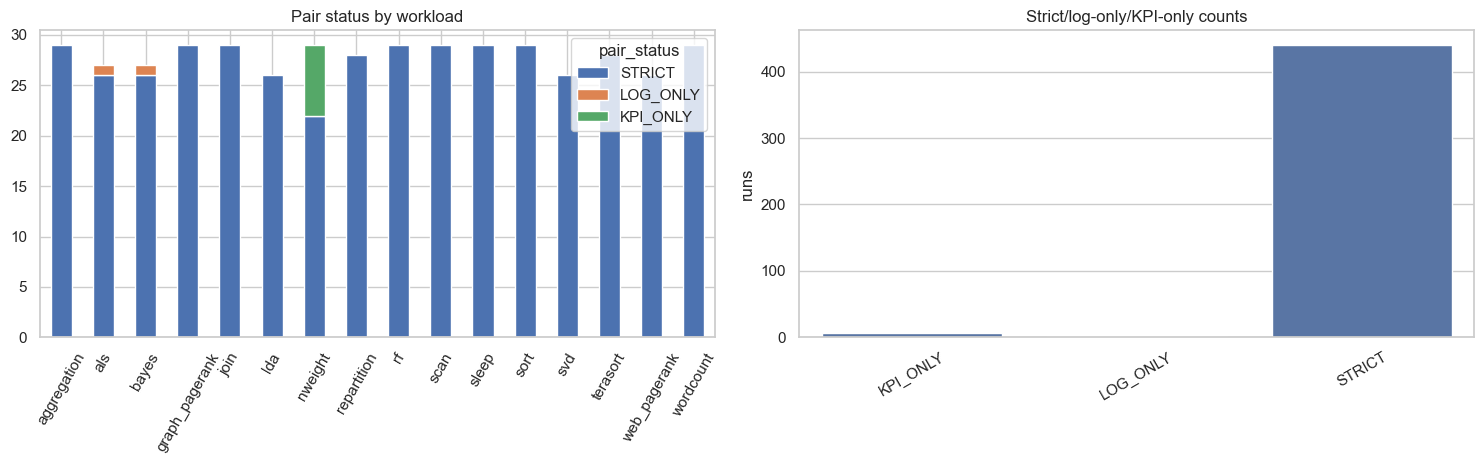


### Локальный вывод раздела

- **Свидетельство:** аудит связки logs↔KPI по `(workload, scenario)`. STRICT path-based пар — **440**, non-STRICT исключений — **9**. Если требовать ещё и workload-level `labeled.csv`, runs с обеими модальностями и parsed labels — **418**.
- **Решение:** сопоставление в новом датасете в основном path-based, но исключения нужно передавать в `02` как явную политику: включение, исключение или резервную обработку.
- **Следствие:** покрытие всё ещё может стать shortcut-сигналом, поэтому отчётность должна включать срезы `kpi_available` и `has_both_modalities`.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
status_pivot = coverage_by_workload_df.pivot(index="workload", columns="pair_status", values="runs").fillna(0)
status_order = [c for c in ["STRICT", "LOG_ONLY", "KPI_ONLY", "MISSING_OR_AMBIGUOUS"] if c in status_pivot.columns]
status_pivot[status_order].plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Статус пары по workload")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=60)
axes[0].legend(title="pair_status")

sns.barplot(data=status_counts_df, x="pair_status", y="runs", ax=axes[1], color="#4C72B0")
axes[1].set_title("Число STRICT/LOG_ONLY/KPI_ONLY")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

strict_runs = int(pairing_audit_df["pair_status"].eq("STRICT").sum())
non_strict_runs = int((~pairing_audit_df["pair_status"].eq("STRICT")).sum())
strict_with_labeled = int(pairing_audit_df["has_both_modalities"].sum())
display(Markdown(f"""
### Локальный вывод раздела

- **Свидетельство:** аудит связки logs↔KPI по `(workload, scenario)`. STRICT path-based пар — **{strict_runs}**, non-STRICT исключений — **{non_strict_runs}**. Если требовать ещё и workload-level `labeled.csv`, runs с обеими модальностями и parsed labels — **{strict_with_labeled}**.
- **Решение:** сопоставление в новом датасете в основном path-based, но исключения нужно передавать в `02` как явную политику: включение, исключение или резервную обработку.
- **Следствие:** покрытие всё ещё может стать shortcut-сигналом, поэтому отчётность должна включать срезы `kpi_available` и `has_both_modalities`.
"""))

## 10. Рабочие гипотезы и правила для `02`

EDA должен завершаться не описанием ради описания, а набором проверяемых правил для baseline pipeline. Таблица ниже превращает наблюдения в инженерно-исследовательские решения.

In [22]:
missing_labeled_workloads = dataset_inventory_df.loc[~dataset_inventory_df["has_labeled_csv"], "workload"].tolist()
non_strict_summary = pairing_audit_df.loc[pairing_audit_df["pair_status"] != "STRICT", ["workload", "scenario", "pair_status"]]
primary_kpi_interval = float(kpi_meta_df.loc[kpi_meta_df["sample_median_interval_sec"].notna(), "sample_median_interval_sec"].median())

rules_df = pd.DataFrame([
    {
        "Наблюдение EDA": "Данные физически организованы как workload/scenario",
        "Факт": f"{len(dataset_inventory_df)} workload, {len(scenario_inventory_df)} runs; STRICT pairs: {strict_runs}",
        "Правило для 02": "Использовать run_id = workload/scenario как базовую единицу наблюдения",
        "Риск, который снимается": "Смешивание разных runs и неверная реконструкция provenance",
    },
    {
        "Наблюдение EDA": "parsed_log/labeled.csv не содержит scenario на уровне строки",
        "Факт": "Template/Label доступны workload-level; scenario-level raw logs лежат отдельно",
        "Правило для 02": "Строить run-level log features из mapred_logs/<scenario>.log; parsed logs использовать как словарь/quality check",
        "Риск, который снимается": "Leakage между scenario внутри одного workload",
    },
    {
        "Наблюдение EDA": "Label=1 — редкие события",
        "Факт": f"row доля положительных строк ≈ {row_positive_share:.3%}; 1min positive windows ≈ {window_positive_share:.3%}",
        "Правило для 02": "Оценивать PR-AUC/precision-recall; accuracy не использовать как главный критерий",
        "Риск, который снимается": "Завышенная оценка на дисбалансных данных",
    },
    {
        "Наблюдение EDA": "Шаблоны имеют частотное ядро и редкий хвост",
        "Факт": f"80% parsed rows покрываются top-{k80} templates; 90% — top-{k90}",
        "Правило для 02": "Агрегировать template/component counts, unique_templates, top-k coverage и log_text",
        "Риск, который снимается": "Потеря интерпретируемых предсбойных маркеров",
    },
    {
        "Наблюдение EDA": "KPI лежат в пробельных instrument-файлах с повторными headers",
        "Факт": f"{len(kpi_meta_df):,} KPI files, total {format_bytes(kpi_meta_df['size_bytes'].sum())}",
        "Правило для 02": "Сделать отдельный устойчивый parser; сохранять host/metric/series/value long representation",
        "Риск, который снимается": "Ошибки чтения KPI и потеря series identity",
    },
    {
        "Наблюдение EDA": "Шкалы KPI неоднородны",
        "Факт": "Value-level sample показывает разные диапазоны и zero-heavy series",
        "Правило для 02": "Нормировать внутри host/metric/series; добавлять zero_share/availability/recency",
        "Риск, который снимается": "Модель учит масштаб метрики вместо изменения состояния",
    },
    {
        "Наблюдение EDA": "KPI sampling interval поддерживает короткие окна",
        "Факт": f"median KPI interval ≈ {primary_kpi_interval:.1f}s",
        "Правило для 02": "Тестировать micro windows 10s/30s для KPI и macro windows 1min/5min для logs",
        "Риск, который снимается": "Размывание краткосрочной предсбойной динамики",
    },
    {
        "Наблюдение EDA": "Есть normal runs и failure families, повторяющиеся между workload",
        "Факт": f"failure families: {', '.join(sorted(set(scenario_inventory_df['failure_family']) - {'normal'}))}",
        "Правило для 02": "Использовать group-aware split по run_id и контролировать leakage по workload/failure_family",
        "Риск, который снимается": "Переобучение на повторяющиеся типы отказов",
    },
    {
        "Наблюдение EDA": "Покрытие не идеально полное",
        "Факт": f"non-STRICT runs: {non_strict_runs}; missing labeled workloads: {missing_labeled_workloads or 'нет'}",
        "Правило для 02": "Отчитывать kpi_available, log_available, has_both_modalities; для non-STRICT задать политику исключения или резервной обработки",
        "Риск, который снимается": "Shortcut через доступность модальности",
    },
    {
        "Наблюдение EDA": "Для failure prediction нужны два горизонта",
        "Факт": "run-level scenario_type задаёт failure context, row/window labels задают локальные события",
        "Правило для 02": "Сформировать dual targets: y_warning для предсбойного горизонта и y_risk/y_anomaly для ближнего события",
        "Риск, который снимается": "Смешение обнаружения текущей аномалии и раннего предупреждения",
    },
    {
        "Наблюдение EDA": "Normal/failure и coverage дают hard negatives",
        "Факт": "Есть normal windows и windows с KPI без Label=1/warning",
        "Правило для 02": "Сохранять hard_negative: KPI/log available, но target=0",
        "Риск, который снимается": "Модель принимает наличие KPI или активность логов за отказ",
    },
])

display(rules_df)

final_policy_df = pd.DataFrame([
    {"Вопрос": "Какие данные идут в 02?", "Решение": "STRICT `(workload, scenario)` runs с raw mapred log и KPI measurements; workload-level parsed logs — как ориентир качества и шаблонов."},
    {"Вопрос": "Что исключать или обрабатывать резервно?", "Решение": "Non-STRICT runs и workload без `labeled.csv` не смешивать с supervised log labels; для них нужна явная резервная обработка или исключение из supervised части."},
    {"Вопрос": "Какие окна — кандидаты?", "Решение": "KPI/log micro: 10s и 30s; log macro context: 1min и 5min."},
    {"Вопрос": "Какие leakage-риски остаются?", "Решение": "Смешивание scenario внутри workload-level labeled logs; повтор failure families между workload; shortcut через KPI/log availability."},
    {"Вопрос": "Какие метрики оценки дальше?", "Решение": "Основная: PR-AUC для y_warning; дополнительная: PR-AUC/recall для y_risk; обязательно coverage-aware slices."},
])

display(Markdown("### Итоговая политика для следующего notebook"))
display(final_policy_df)

,Наблюдение EDA,Факт,Правило для 02,"Риск, который снимается"
0,Данные физически организованы как workload/scenario,"16 workload, 449 runs; STRICT pairs: 440",Использовать run_id = workload/scenario как базовую единицу наблюдения,Смешивание разных runs и неверная реконструкция provenance
1,parsed_log/labeled.csv не содержит scenario на уровне строки,Template/Label доступны workload-level; scenario-level raw logs лежат отдельно,Строить run-level log features из mapred_logs/<scenario>.log; parsed logs использовать как словарь/quality check,Leakage между scenario внутри одного workload
2,Label=1 — редкие события,row positive share ≈ 0.195%; 1min positive windows ≈ 10.145%,Оценивать PR-AUC/precision-recall; accuracy не использовать как главный критерий,Завышенная оценка на дисбалансных данных
3,Шаблоны имеют частотное ядро и редкий хвост,80% parsed rows покрываются top-24 templates; 90% — top-46,"Агрегировать template/component counts, unique_templates, top-k coverage и log_text",Потеря интерпретируемых предсбойных маркеров
4,KPI лежат в пробельных instrument-файлах с повторными headers,"16,093 KPI files, total 3.6 GB",Сделать отдельный устойчивый parser; сохранять host/metric/series/value long representation,Ошибки чтения KPI и потеря series identity
5,Шкалы KPI неоднородны,Value-level sample показывает разные диапазоны и zero-heavy series,Нормировать внутри host/metric/series; добавлять zero_share/availability/recency,Модель учит масштаб метрики вместо изменения состояния
6,KPI sampling interval поддерживает короткие окна,median KPI interval ≈ 1.0s,Тестировать micro windows 10s/30s для KPI и macro windows 1min/5min для logs,Размывание краткосрочной предсбойной динамики
7,"Есть normal runs и failure families, повторяющиеся между workload","failure families: cpu, datanode, io, master, memory, namenode, network, nodemanager, resourcemanager, timing, worker",Использовать group-aware split по run_id и контролировать leakage по workload/failure_family,Переобучение на повторяющиеся типы отказов
8,Покрытие не идеально полное,non-STRICT runs: 9; missing labeled workloads: ['nweight'],"Отчитывать kpi_available, log_available, has_both_modalities; для non-STRICT задать политику исключения или резервной обработки",Shortcut через доступность модальности
9,Для failure prediction нужны два горизонта,"run-level scenario_type задаёт failure context, row/window labels задают локальные события",Сформировать dual targets: y_warning для предсбойного горизонта и y_risk/y_anomaly для ближнего события,Смешение обнаружения текущей аномалии и раннего предупреждения


### Итоговая политика для следующего notebook

,Вопрос,Решение
0,Какие данные идут в 02?,"STRICT `(workload, scenario)` runs с raw mapred log и KPI measurements; workload-level parsed logs — как quality/tem..."
1,Что исключать или обрабатывать резервно?,Non-STRICT runs и workload без `labeled.csv` не смешивать с supervised log labels; для них нужна резервная обработка или ...
2,Какие окна — кандидаты?,KPI/log micro: 10s и 30s; log macro context: 1min и 5min.
3,Какие leakage-риски остаются?,Смешивание scenario внутри workload-level labeled logs; повтор failure families между workload; shortcut через KPI/l...
4,Какие метрики оценки дальше?,Primary: PR-AUC для y_warning; secondary: PR-AUC/recall для y_risk; обязательно coverage-aware slices.


## Финальный вывод notebook

`raw_data/` подходит для исследовательской multi-rate AIOps постановки, но требует дисциплины provenance:

- единица наблюдения — **`run_id = workload/scenario`**;
- strict сопоставление logs↔KPI в основном задаётся путями, но non-STRICT исключения фиксируются до baseline;
- `parsed_log/labeled.csv` полезен для шаблонов, компонент и sanity-check `Label`, но не является строгим scenario-level журналом;
- KPI надо читать отдельным parser-ом и хранить как **series-aware** модальность `host/metric/series`;
- baseline в `02` должен быть coverage-aware, group-aware и multi-rate: короткие KPI окна + более широкий log macro context;
- ключевые ограничения для текста ВКР: неполная scenario-разметка parsed logs, неполный coverage отдельных runs, неоднородность KPI scales и риск shortcut через доступность модальностей.

## Refactor notes

Временный технический блок для следующего прохода; в финальной версии notebook его нужно удалить.

- **keep:** роль `01` как EDA; `run_id = workload/scenario`; strict path-based provenance logs↔KPI; раздельное использование workload-level `parsed_log/labeled.csv` и scenario-level raw logs/KPI; multi-rate windows 10s/30s и 1min/5min.
- **move-to-src:** `safe_dirs/safe_files`, классификация scenario/failure family, `scan_raw_data_inventory`, `load_labeled_logs`, raw-log parser, KPI file index parser, `parse_instrument_file`, выборка value-level KPI.
- **compress-output:** полные inventory/KPI/raw-log паспорта на следующем проходе лучше сохранять как отчётные артефакты, а в notebook оставлять head/top rows и один локальный вывод.
- **delete:** traceback/object-repr outputs удалены; GPT-подобные блоки переписаны в схему «свидетельство → решение → следствие».
- **needs-clean-run:** текущие outputs были частично выполнены не по порядку; после выноса helper-функций нужен полный чистый запуск, особенно для логового блока, scenario imbalance и KPI parsing/sample cells.
